# Spotify 오디오 특성 군집화 프로젝트 — test3 (k-pop 장르 subset)

이 노트북은 test2의 분석 흐름을 유지하고, 분석 대상을 `track_genre == "k-pop"`인 행으로 제한합니다.

분석 순서: 데이터 설명 및 EDA → 전처리 → K-Means 베이스라인 → 다른 군집화 비교 및 파라미터 탐색 → 최종 모델 선택 → 군집 내 KNN 추천 로직 → 통계 검정 및 결과 해석 → 최종 시각화

- 이 필터는 데이터셋의 `k-pop` 장르 라벨을 기준으로 합니다. 한국 가수 국적을 뜻하는 것은 아니며, 라벨이 붙은 비한국 아티스트가 포함될 수도 있습니다.
- 추천용 입력은 오디오 특성입니다. `popularity`, 곡 정보, `explicit`, 장르는 군집화 입력에서 제외합니다.
- `track_genre`는 분석 대상을 고르는 필터와 EDA 확인에만 사용하고 모델 입력에는 넣지 않습니다.
- 주관적인 청취 평점으로 가중치를 정하는 과정은 사용자 데이터가 생긴 뒤로 미룹니다.
- 수업의 가설검정은 최종 군집을 만든 다음, 군집에 사용하지 않은 popularity와 군집의 관계를 살펴보는 데 적용합니다.


In [97]:
from pathlib import Path
from itertools import combinations

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from scipy.stats import kruskal, mannwhitneyu

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN, MeanShift, estimate_bandwidth
from sklearn.mixture import GaussianMixture
from sklearn.metrics import (
    silhouette_score,
    silhouette_samples,
    davies_bouldin_score,
    calinski_harabasz_score,
)
from sklearn.neighbors import NearestNeighbors
from sklearn.decomposition import PCA
from threadpoolctl import threadpool_limits

# Apple SD Gothic Neo keeps Korean readable; Arial Unicode MS fills accented Latin glyphs in track names.
plt.rcParams["font.family"] = ["Apple SD Gothic Neo", "Arial Unicode MS"]

RANDOM_STATE = 42
GENRE_FILTER = "k-pop"

# 노트북을 project2 폴더에서 열거나 저장소 루트에서 열어도 데이터 파일을 찾도록 합니다.
data_candidates = [
    Path("spotify_tracks_dataset/dataset.csv"),
    Path("project2/spotify_tracks_dataset/dataset.csv"),
]
DATA_PATH = next((path for path in data_candidates if path.exists()), None)
if DATA_PATH is None:
    raise FileNotFoundError(
        "spotify_tracks_dataset/dataset.csv를 찾지 못했습니다. "
        "project2 폴더 또는 저장소 루트에서 노트북을 실행해 주세요."
    )

df_source = pd.read_csv(DATA_PATH)
print(f"읽은 파일: {DATA_PATH}")
print(f"전체 데이터 크기: {df_source.shape[0]:,}행 × {df_source.shape[1]}열")
if "track_genre" not in df_source.columns:
    raise KeyError("track_genre 열이 없어 k-pop 장르 필터를 적용할 수 없습니다.")

# 모든 EDA와 전처리보다 먼저 k-pop 장르 라벨만 남깁니다.
genre_mask = (
    df_source["track_genre"].astype("string").str.strip().str.casefold()
    == GENRE_FILTER.casefold()
)
df_raw = df_source.loc[genre_mask].copy()
print(f"분석 대상 필터: track_genre == {GENRE_FILTER!r}")
print(f"필터 후 크기: {df_raw.shape[0]:,}행 × {df_raw.shape[1]}열")
if "track_id" in df_raw.columns:
    print(f"필터 후 고유 track_id: {df_raw['track_id'].nunique():,}개")
if df_raw.empty:
    raise ValueError(f"track_genre == {GENRE_FILTER!r}인 행이 없습니다.")
display(df_raw["track_genre"].value_counts(dropna=False).to_frame("필터 결과 행 수"))
del df_source


읽은 파일: spotify_tracks_dataset/dataset.csv
전체 데이터 크기: 114,000행 × 21열
분석 대상 필터: track_genre == 'k-pop'
필터 후 크기: 1,000행 × 21열
필터 후 고유 track_id: 999개


,필터 결과 행 수
k-pop,1000


## 1. 데이터 설명

각 열의 역할을 먼저 구분합니다. 이 노트북의 EDA와 분석은 앞 단계에서 선택한 `k-pop` 장르 라벨 행만 대상으로 합니다. 이 라벨은 한국 가수 국적 인증 정보가 아닙니다.

모델에 넣는 값과 화면 표시·필터·결과 해석에만 쓰는 값은 다릅니다.


In [98]:
column_guide = [
    ("track_id", "곡의 고유 ID", "추천 결과 연결·중복 확인"),
    ("track_name", "곡 제목", "화면 표시"),
    ("artists", "아티스트 이름", "화면 표시"),
    ("album_name", "앨범 이름", "화면 표시"),
    ("popularity", "데이터셋의 인기도 점수(보통 0~100)", "군집화 입력 제외, 외부 결과 검정·해석"),
    ("duration_ms", "곡 길이(밀리초; log1p 변환 버전도 비교)", "오디오 특성 입력"),
    ("explicit", "explicit 콘텐츠 여부", "선택적 화면 필터, 군집화 입력 제외"),
    ("danceability", "춤추기 쉬운 정도 추정치(0~1)", "오디오 특성 입력"),
    ("energy", "곡의 강도·활동성 추정치(0~1)", "오디오 특성 입력"),
    ("key", "곡의 조성 코드(0~11; 실제 분포는 아래에서 확인)", "범주형으로 원-핫 인코딩"),
    ("loudness", "평균 음량(dB)", "오디오 특성 입력"),
    ("mode", "장조(1) / 단조(0)", "범주형으로 원-핫 인코딩"),
    ("speechiness", "말소리 비중 추정치(0~1)", "오디오 특성 입력"),
    ("acousticness", "어쿠스틱한 정도 추정치(0~1)", "오디오 특성 입력"),
    ("instrumentalness", "보컬이 없을 가능성 추정치(0~1)", "오디오 특성 입력"),
    ("liveness", "라이브 공연 녹음일 가능성 추정치(0~1)", "오디오 특성 입력"),
    ("valence", "음악의 긍정적·밝은 정도 추정치(0~1)", "오디오 특성 입력"),
    ("tempo", "템포(BPM)", "오디오 특성 입력"),
    ("time_signature", "박자표(예: 3/4, 4/4를 나타내는 값)", "범주형으로 원-핫 인코딩"),
    ("track_genre", "데이터셋의 세부 장르 라벨", "EDA에서만 확인, 모델 입력 제외"),
    ("Unnamed: 0", "CSV 저장 과정에서 생긴 행 번호", "전처리에서 제거"),
]
display(pd.DataFrame(column_guide, columns=["열", "설명", "프로젝트에서의 역할"]))

,열,설명,프로젝트에서의 역할
0,track_id,곡의 고유 ID,추천 결과 연결·중복 확인
1,track_name,곡 제목,화면 표시
2,artists,아티스트 이름,화면 표시
3,album_name,앨범 이름,화면 표시
4,popularity,데이터셋의 인기도 점수(보통 0~100),"군집화 입력 제외, 외부 결과 검정·해석"
5,duration_ms,곡 길이(밀리초; log1p 변환 버전도 비교),오디오 특성 입력
6,explicit,explicit 콘텐츠 여부,"선택적 화면 필터, 군집화 입력 제외"
7,danceability,춤추기 쉬운 정도 추정치(0~1),오디오 특성 입력
8,energy,곡의 강도·활동성 추정치(0~1),오디오 특성 입력
9,key,곡의 조성 코드(0~11; 실제 분포는 아래에서 확인),범주형으로 원-핫 인코딩


In [99]:
print("데이터 미리보기")
display(df_raw.head())

print("자료형")
display(df_raw.dtypes.rename("dtype").to_frame())

print("결측값 수")
display(df_raw.isna().sum().sort_values(ascending=False).rename("결측 수").to_frame())

print("숫자형 요약 통계")
display(df_raw.select_dtypes(include="number").describe().T)

데이터 미리보기


,Unnamed: 0,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,...,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
65000,65000,3hkC9EHFZNQPXrtl8WPHnX,Alka Yagnik;Arijit Singh,Tamasha,Agar Tum Saath Ho,73,341054,False,0.562,0.519,...,-8.744,1,0.0326,0.5570,0.000268,0.1720,0.415,122.925,4,k-pop
65001,65001,45OX2jjEw1l7lOFJfDP9fv,LISA,LALISA,MONEY,78,168227,False,0.826,0.553,...,-10.121,0,0.2340,0.1630,0.000041,0.1350,0.400,140.037,4,k-pop
65002,65002,5aucVLKiumD89mxVCB4zvS,Crush;j-hope,Rush Hour,Rush Hour (Feat. j-hope of BTS),83,177302,False,0.738,0.714,...,-5.235,1,0.2490,0.1570,0.000000,0.3100,0.740,95.035,4,k-pop
65003,65003,1R0hxCA5R7z5TiaXBZR7Mf,JENNIE,SOLO,SOLO,73,169566,False,0.752,0.642,...,-5.165,0,0.0869,0.0861,0.000000,0.0953,0.388,95.043,4,k-pop
65004,65004,4a9tbd947vo9K8Vti9JwcI,BTS;Halsey,MAP OF THE SOUL : PERSONA,Boy With Luv (feat. Halsey),80,229773,False,0.645,0.862,...,-4.761,0,0.0845,0.0933,0.000000,0.1930,0.803,119.947,4,k-pop


자료형


,dtype
Unnamed: 0,int64
track_id,object
artists,object
album_name,object
track_name,object
popularity,int64
duration_ms,int64
explicit,bool
danceability,float64
energy,float64


결측값 수


,결측 수
artists,1
album_name,1
track_name,1
Unnamed: 0,0
mode,0
time_signature,0
tempo,0
valence,0
liveness,0
instrumentalness,0


숫자형 요약 통계


,count,mean,std,min,25%,50%,75%,max
Unnamed: 0,1000.0,65499.500000,288.819436,65000.000000,65249.750000,65499.500000,65749.25000,65999.000
popularity,1000.0,56.896000,16.946456,0.000000,48.000000,60.000000,69.00000,88.000
duration_ms,1000.0,251277.169000,159190.592714,0.000000,195863.250000,229773.000000,282976.25000,3340672.000
danceability,1000.0,0.647732,0.135423,0.206000,0.562000,0.656000,0.74025,0.935
energy,1000.0,0.675654,0.176292,0.166000,0.550500,0.701000,0.81800,0.993
key,1000.0,5.328000,3.588216,0.000000,2.000000,6.000000,8.00000,11.000
loudness,1000.0,-6.470775,2.922321,-18.064000,-8.332500,-6.135000,-4.31175,-0.173
mode,1000.0,0.519000,0.499889,0.000000,0.000000,1.000000,1.00000,1.000
speechiness,1000.0,0.088024,0.086242,0.023800,0.037375,0.056700,0.10200,0.889
acousticness,1000.0,0.292968,0.281279,0.000253,0.037600,0.188000,0.51200,0.981


## 2. EDA

결측·중복·값의 범위를 살피고, 특히 길이와 오디오 특성의 분포를 확인합니다. 분포가 한쪽으로 치우쳤다는 이유만으로 행을 지우지는 않습니다.

분석 장르 라벨: k-pop
track_id 중복 행 수: 1
duration_ms이 0인 행 수: 1
tempo이 0인 행 수: 0
time_signature이 0인 행 수: 0

explicit 비율


,행 수
False,951
True,49


,비율(%)
False,95.1
True,4.9


,행 수
조성,
C♯/D♭,119
C,114
A,97
G♯/A♭,94
G,94
F,92
D,79
B,77
F♯/G♭,74


,왜도
duration_ms,13.351348
danceability,-0.325912
energy,-0.459420
loudness,-0.639888
speechiness,3.190658
acousticness,0.734509
instrumentalness,10.312831
liveness,1.904904
valence,-0.135532
tempo,0.455012


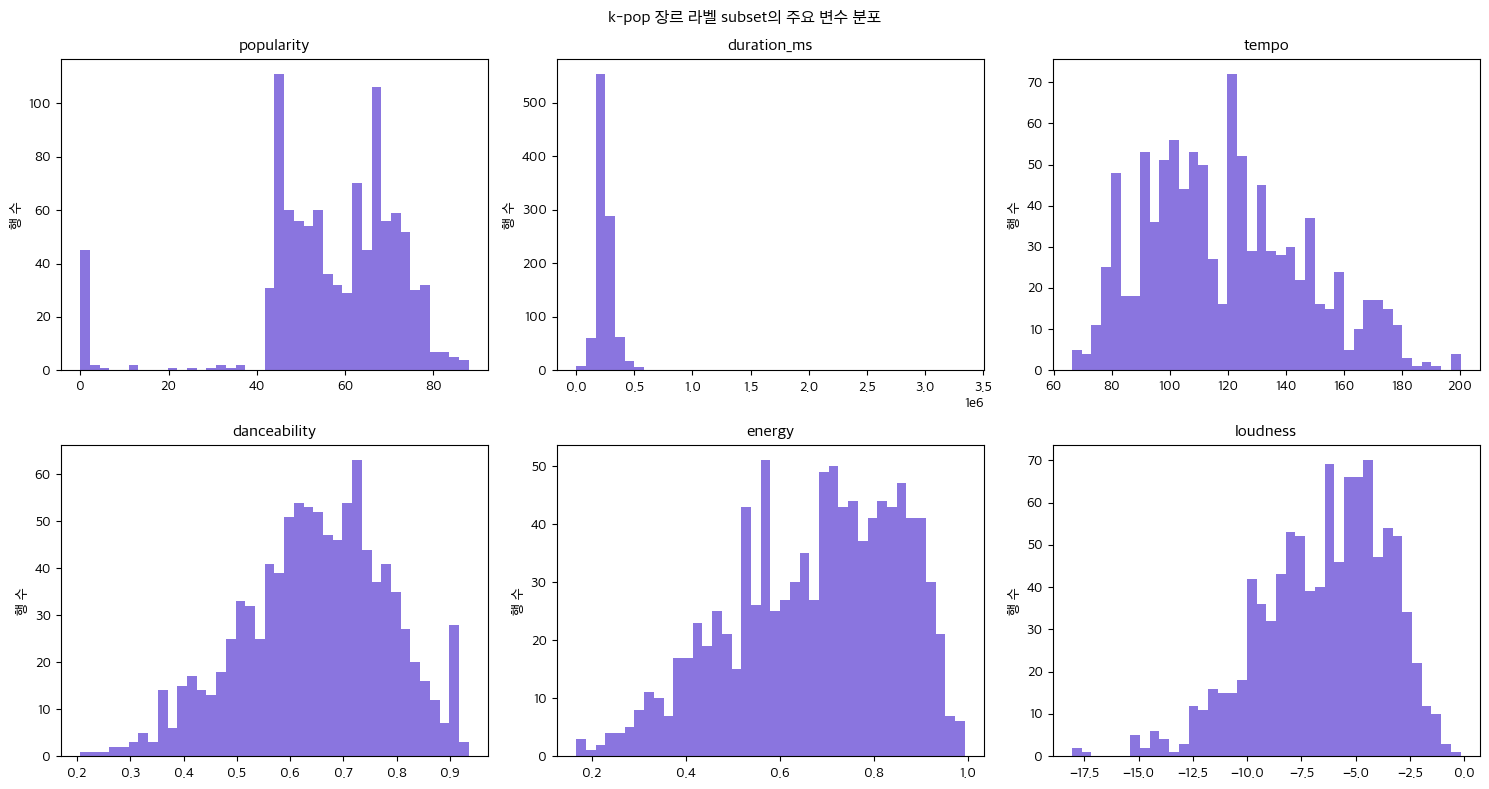

,행 수
장르 라벨,
k-pop,1000


In [100]:
print(f"분석 장르 라벨: {GENRE_FILTER}")
print(f"track_id 중복 행 수: {df_raw['track_id'].duplicated().sum():,}")
for column in ["duration_ms", "tempo", "time_signature"]:
    if column in df_raw.columns:
        print(f"{column}이 0인 행 수: {(df_raw[column] == 0).sum():,}")

if "explicit" in df_raw.columns:
    print("\nexplicit 비율")
    display(df_raw["explicit"].value_counts(dropna=False).to_frame("행 수"))
    display((df_raw["explicit"].value_counts(normalize=True, dropna=False) * 100)
            .round(2).rename("비율(%)").to_frame())

key_names = {-1: "미상", 0: "C", 1: "C♯/D♭", 2: "D", 3: "D♯/E♭",
             4: "E", 5: "F", 6: "F♯/G♭", 7: "G", 8: "G♯/A♭",
             9: "A", 10: "A♯/B♭", 11: "B"}
if "key" in df_raw.columns:
    key_counts = df_raw["key"].map(key_names).fillna("기타/결측")
    display(key_counts.value_counts(dropna=False).rename_axis("조성").to_frame("행 수"))

audio_numeric = [
    "duration_ms", "danceability", "energy", "loudness", "speechiness",
    "acousticness", "instrumentalness", "liveness", "valence", "tempo",
]
available_audio = [c for c in audio_numeric if c in df_raw.columns]
display(df_raw[available_audio].skew(numeric_only=True).rename("왜도").to_frame())

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
plot_columns = ["popularity", "duration_ms", "tempo", "danceability",
                "energy", "loudness"]
for ax, column in zip(axes.flat, plot_columns):
    if column in df_raw.columns:
        ax.hist(df_raw[column].dropna(), bins=40, color="#7057d9", alpha=0.82)
        ax.set_title(column)
        ax.set_ylabel("행 수")
    else:
        ax.set_visible(False)
plt.suptitle("k-pop 장르 라벨 subset의 주요 변수 분포")
plt.tight_layout()
plt.show()

# 필터가 의도대로 적용되었는지 확인합니다. 여기서는 k-pop만 보여야 합니다.
display(df_raw["track_genre"].value_counts(dropna=False).rename_axis("장르 라벨").to_frame("행 수"))


## 3. 전처리와 특성 구성

`track_genre == "k-pop"` subset을 대상으로 합니다. 전처리에서 행을 제외하기 전에 원본 CSV 행 번호와 사유를 담은 엑셀 검수 보고서를 저장합니다. 필수 분석값 결측/형식 오류와 duration·tempo·time_signature의 0 이하 값은 현재 제외 기준으로 기록하고, loudness > 0은 수동 검토 후보로 별도 기록합니다. loudness 후보는 보고서 확인 전에는 자동 삭제하지 않습니다.

검수 보고서 생성 후 확정된 기준을 적용하고, 남은 중복 track_id는 대표 행 하나를 유지하면서 popularity를 유효 행들의 평균으로 대체합니다. 나머지 컬럼은 대표 행 값을 유지합니다.

연속형 특성은 StandardScaler로 표준화하고, key·mode·time_signature는 범주형으로 원-핫 인코딩합니다. 곡 길이는 원본과 log1p 변환본을 간단한 군집 품질 지표로 비교한 뒤 선택합니다. popularity와 화면 표시용 텍스트·장르는 모델 입력에서 제외합니다.


In [101]:
continuous_cols = [
    "duration_ms", "danceability", "energy", "loudness", "speechiness",
    "acousticness", "instrumentalness", "liveness", "valence", "tempo",
]
required_cols = continuous_cols + [
    "track_id", "popularity", "key", "mode", "time_signature",
]
missing_columns = [c for c in required_cols if c not in df_raw.columns]
if missing_columns:
    raise KeyError(f"필요한 열이 없습니다: {missing_columns}")

df = df_raw.drop(columns=["Unnamed: 0"], errors="ignore").copy()

numeric_needed = continuous_cols + ["popularity", "key", "mode", "time_signature"]
df[numeric_needed] = df[numeric_needed].apply(pd.to_numeric, errors="coerce")

before = len(df)

# 엑셀 보고서를 먼저 만들어 원본 CSV의 어느 행이 왜 표시되는지 확인할 수 있게 합니다.
quality_rules = {
    "필수 분석 컬럼 결측/형식 오류": df[required_cols].isna().any(axis=1),
    "duration_ms <= 0": df["duration_ms"] <= 0,
    "tempo <= 0": df["tempo"] <= 0,
    "time_signature <= 0": df["time_signature"] <= 0,
    "loudness > 0 (수동 검토)": df["loudness"] > 0,
}
confirmed_exclusion_mask = (
    quality_rules["필수 분석 컬럼 결측/형식 오류"]
    | quality_rules["duration_ms <= 0"]
    | quality_rules["tempo <= 0"]
    | quality_rules["time_signature <= 0"]
)
loudness_review_mask = quality_rules["loudness > 0 (수동 검토)"]
flagged_mask = confirmed_exclusion_mask | loudness_review_mask
audit_df = df.loc[flagged_mask].copy()
audit_df.insert(0, "원본 CSV 행", audit_df.index + 2)
audit_df["검토 사유"] = [
    "; ".join(rule for rule, mask in quality_rules.items() if bool(mask.loc[index]))
    for index in audit_df.index
]
audit_df["현재 처리"] = [
    "분석 제외 기준 해당" if bool(confirmed_exclusion_mask.loc[index]) else "엑셀 확인 후 결정"
    for index in audit_df.index
]

summary_rows = []
for rule, mask in quality_rules.items():
    summary_rows.append({
        "검사 기준": rule,
        "해당 행 수": int(mask.sum()),
        "고유 곡 수": int(df.loc[mask, "track_id"].nunique()),
        "조치": "보고서 확인 후 결정" if "수동 검토" in rule else "현재 전처리에서 제외",
    })
summary_rows.append({
    "검사 기준": "전체 검토 대상 (중복 사유는 행당 1회 집계)",
    "해당 행 수": int(flagged_mask.sum()),
    "고유 곡 수": int(df.loc[flagged_mask, "track_id"].nunique()),
    "조치": "상세 시트에서 사유 확인",
})
quality_summary = pd.DataFrame(summary_rows)
report_path = DATA_PATH.parent.parent / "reports" / "test3_data_quality_review.xlsx"
report_path.parent.mkdir(parents=True, exist_ok=True)
try:
    with pd.ExcelWriter(report_path, engine="openpyxl") as writer:
        quality_summary.to_excel(writer, sheet_name="요약", index=False)
        audit_df.to_excel(writer, sheet_name="전체_검토", index=False)
        audit_df.loc[confirmed_exclusion_mask.loc[audit_df.index]].to_excel(
            writer, sheet_name="확정_제외대상", index=False
        )
        audit_df.loc[loudness_review_mask.loc[audit_df.index]].to_excel(
            writer, sheet_name="loudness_양수검토", index=False
        )
except ImportError as error:
    raise ImportError("엑셀 보고서 저장에는 openpyxl이 필요합니다. 노트북에서 %pip install openpyxl 을 실행하세요.") from error
print(f"데이터 품질 검수 보고서 저장: {report_path}")
display(quality_summary)

# 검수 후 loudness 양수값을 오류로 확정하면 True로 변경하고 이 셀부터 다시 실행합니다.
EXCLUDE_POSITIVE_LOUDNESS = True

df = df.dropna(subset=required_cols).copy()
after_missing = len(df)
df = df[df["duration_ms"] > 0].copy()
after_duration = len(df)
df = df[(df["tempo"] > 0) & (df["time_signature"] > 0)].copy()
after_invalid_audio = len(df)
positive_loudness_before = int((df["loudness"] > 0).sum())
rows_before_loudness = len(df)
if EXCLUDE_POSITIVE_LOUDNESS:
    df = df[df["loudness"] <= 0].copy()
after_loudness = len(df)

duplicate_track_ids = df.loc[
    df["track_id"].duplicated(keep=False), "track_id"
].nunique()
popularity_mean_by_track = df.groupby("track_id")["popularity"].mean()
# 대표 행 선택·정렬은 유지하면서, 인기 점수만 유효 중복 행의 평균으로 바꿉니다.
df = (
    df.sort_values("popularity", ascending=False, na_position="last")
      .drop_duplicates(subset="track_id", keep="first")
      .copy()
)
df["popularity"] = df["track_id"].map(popularity_mean_by_track)
after_duplicates = len(df)
df = df.reset_index(drop=True)

print(f"필수값 결측 제거: {before:,} → {after_missing:,}행")
print(f"duration_ms 0 이하 제거: {after_missing:,} → {after_duration:,}행")
print(f"tempo/time_signature 0 제거: {after_duration:,} → {after_invalid_audio:,}행")
if EXCLUDE_POSITIVE_LOUDNESS:
    print(f"loudness > 0 확정 제외: {positive_loudness_before:,}행 제거 ({rows_before_loudness:,} → {after_loudness:,}행)")
else:
    print(f"loudness > 0 검수 후보: {positive_loudness_before:,}행 (현재 유지)")
print(f"중복 track_id 정리 (평균 popularity 적용): {after_loudness:,} → {after_duplicates:,}행")
print(f"평균 popularity를 적용한 중복 곡 ID 수: {duplicate_track_ids:,}")
print(f"최종 분석 행 수: {len(df):,}")

데이터 품질 검수 보고서 저장: reports/test3_data_quality_review.xlsx


,검사 기준,해당 행 수,고유 곡 수,조치
0,필수 분석 컬럼 결측/형식 오류,0,0,현재 전처리에서 제외
1,duration_ms <= 0,1,1,현재 전처리에서 제외
2,tempo <= 0,0,0,현재 전처리에서 제외
3,time_signature <= 0,0,0,현재 전처리에서 제외
4,loudness > 0 (수동 검토),0,0,보고서 확인 후 결정
5,전체 검토 대상 (중복 사유는 행당 1회 집계),1,1,상세 시트에서 사유 확인


필수값 결측 제거: 1,000 → 1,000행
duration_ms 0 이하 제거: 1,000 → 999행
tempo/time_signature 0 제거: 999 → 999행
loudness > 0 확정 제외: 0행 제거 (999 → 999행)
중복 track_id 정리 (평균 popularity 적용): 999 → 998행
평균 popularity를 적용한 중복 곡 ID 수: 1
최종 분석 행 수: 998


곡 길이 왜도 비교 (절댓값이 작을수록 덜 치우친 분포)


,왜도
duration_ms 원본,13.412202
log1p(duration_ms),1.374592


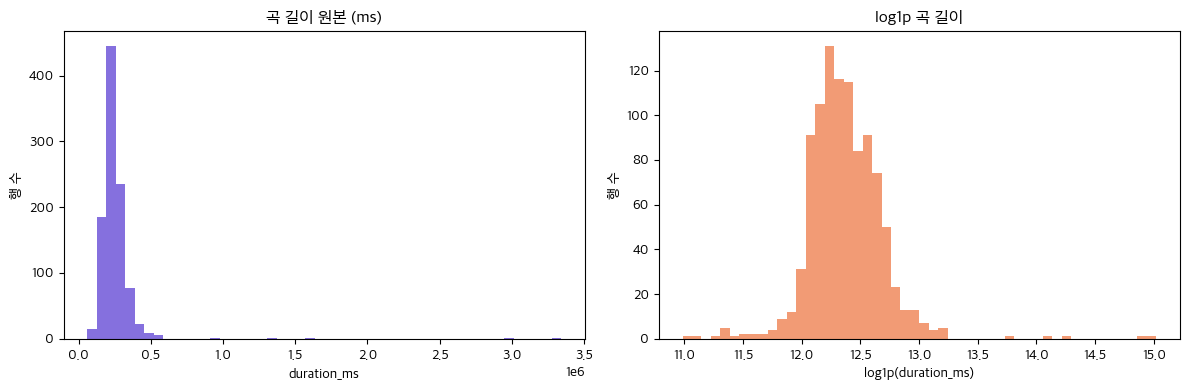

duration 버전,log1p,raw
K,,
2,0.2033,0.2029
3,0.2023,0.1702
4,0.1370,0.1385
5,0.1299,0.0997
6,0.1319,0.1155
7,0.1112,0.1247
8,0.1037,0.1237
9,0.1055,0.1076
10,0.0988,0.1132


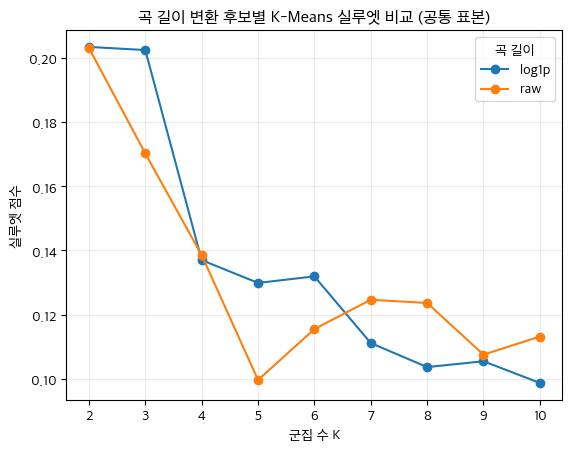

최종 곡 길이 처리: raw
최종 모델 입력 행·열: (998, 28)
연속형 열: ['duration_ms', 'danceability', 'energy', 'loudness', 'speechiness', 'acousticness', 'instrumentalness', 'liveness', 'valence', 'tempo']
원-핫 인코딩 열: ['key_0', 'key_1', 'key_10', 'key_11', 'key_2', 'key_3', 'key_4', 'key_5', 'key_6', 'key_7', 'key_8', 'key_9', 'mode_0', 'mode_1', 'time_signature_1', 'time_signature_3', 'time_signature_4', 'time_signature_5']


,duration_ms,danceability,energy,loudness,speechiness,acousticness,instrumentalness,liveness,valence,tempo,...,key_6,key_7,key_8,key_9,mode_0,mode_1,time_signature_1,time_signature_3,time_signature_4,time_signature_5
0,-0.470161,0.238516,1.395992,1.797390,0.383582,-0.673599,-0.139791,-0.686663,1.192539,0.211220,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0
1,-0.476980,1.221354,-0.106908,0.006141,-0.588565,-1.031008,-0.139791,0.050442,0.464709,-0.335274,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0
2,-0.467060,0.918374,1.310923,1.378679,0.418384,-0.556018,-0.139791,1.218363,1.113855,0.027083,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0
3,-0.489197,1.901212,-0.640013,0.112959,0.163167,-0.950091,-0.139653,-0.490978,-1.143403,-0.446867,...,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0
4,-0.365610,-0.655645,1.186153,0.667588,1.172436,-0.886669,-0.139791,1.210629,0.622077,1.928581,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0


In [102]:
# 원본 곡 길이와 log1p 곡 길이의 분포 및 K-Means 실루엣을 같은 표본에서 비교합니다.
df["duration_log1p"] = np.log1p(df["duration_ms"])
print("곡 길이 왜도 비교 (절댓값이 작을수록 덜 치우친 분포)")
display(pd.Series({"duration_ms 원본": df["duration_ms"].skew(),
                   "log1p(duration_ms)": df["duration_log1p"].skew()}, name="왜도").to_frame())

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(df["duration_ms"], bins=50, color="#7057d9", alpha=0.85)
axes[0].set_title("곡 길이 원본 (ms)")
axes[0].set_xlabel("duration_ms")
axes[0].set_ylabel("행 수")
axes[1].hist(df["duration_log1p"], bins=50, color="#f08a5d", alpha=0.85)
axes[1].set_title("log1p 곡 길이")
axes[1].set_xlabel("log1p(duration_ms)")
axes[1].set_ylabel("행 수")
plt.tight_layout()
plt.show()

# 범주형 세 특성은 모든 후보에서 똑같이 원-핫 인코딩합니다.
categorical = df[["key", "mode", "time_signature"]].astype(int).astype(str)
X_categorical = pd.get_dummies(
    categorical,
    columns=["key", "mode", "time_signature"],
    prefix=["key", "mode", "time_signature"],
    dtype=np.float32,
)
X_categorical.index = df.index
sample_positions = np.random.RandomState(RANDOM_STATE).choice(
    len(df), size=min(1200, len(df)), replace=False
)
duration_rows = []
for version in ["raw", "log1p"]:
    candidate_continuous = df[continuous_cols].copy()
    candidate_continuous["duration_ms"] = (
        df["duration_ms"] if version == "raw" else df["duration_log1p"]
    )
    candidate_scaled = StandardScaler().fit_transform(candidate_continuous)
    candidate_X = np.column_stack([candidate_scaled, X_categorical.to_numpy()])
    candidate_sample = candidate_X[sample_positions]
    for k in range(2, 11):
        with threadpool_limits(limits=1):
            candidate_labels = KMeans(
                n_clusters=k, random_state=RANDOM_STATE, n_init=10
            ).fit_predict(candidate_sample)
        duration_rows.append({
            "duration 버전": version,
            "K": k,
            "실루엣 점수": silhouette_score(candidate_sample, candidate_labels),
        })
duration_comparison = pd.DataFrame(duration_rows)
display(duration_comparison.pivot(index="K", columns="duration 버전", values="실루엣 점수").round(4))
for version, group in duration_comparison.groupby("duration 버전"):
    plt.plot(group["K"], group["실루엣 점수"], marker="o", label=version)
plt.title("곡 길이 변환 후보별 K-Means 실루엣 비교 (공통 표본)")
plt.xlabel("군집 수 K")
plt.ylabel("실루엣 점수")
plt.xticks(range(2, 11))
plt.legend(title="곡 길이")
plt.grid(alpha=0.25)
plt.show()

# 위 분포·점수를 확인한 뒤 raw 또는 log1p로 선택합니다.
DURATION_VERSION = "raw"  # 비교 후 log1p를 쓰려면 "log1p"로 변경
if DURATION_VERSION not in {"raw", "log1p"}:
    raise ValueError("DURATION_VERSION은 'raw' 또는 'log1p'여야 합니다.")
duration_feature = "duration_ms" if DURATION_VERSION == "raw" else "duration_log1p"
model_continuous = df[continuous_cols].drop(columns="duration_ms").copy()
model_continuous.insert(0, duration_feature, df[duration_feature])
continuous_model_cols = model_continuous.columns.tolist()
scaler = StandardScaler()
X_continuous = pd.DataFrame(
    scaler.fit_transform(model_continuous),
    columns=continuous_model_cols,
    index=df.index,
)

X = pd.concat([X_continuous, X_categorical], axis=1).astype("float32")
assert "popularity" not in X.columns and "track_id" not in X.columns
assert "track_genre" not in X.columns and len(X) == len(df)

track_info = df[
    [c for c in ["track_id", "track_name", "artists", "album_name",
                 "popularity", "explicit", "track_genre"] if c in df.columns]
].copy()
print(f"최종 곡 길이 처리: {DURATION_VERSION}")
print(f"최종 모델 입력 행·열: {X.shape}")
print(f"연속형 열: {continuous_model_cols}")
print(f"원-핫 인코딩 열: {X_categorical.columns.tolist()}")
display(X.head())

## 군집화 직전: 최종 전처리 데이터 확인

먼저 최종 특성의 스케일링 전 분포를 보고, 이어서 같은 특성을 StandardScaler로 표준화한 뒤 분포를 비교합니다. 마지막 그래프는 원-핫 범주 비율입니다. 모두 군집화에 실제 사용할 특성이고 popularity는 포함하지 않습니다.

최종 모델 입력 크기: (998, 28)  |  duration 버전: raw
연속형 특성 평균 범위: -0.000 ~ 0.000
연속형 특성 표준편차 범위: 1.001 ~ 1.001


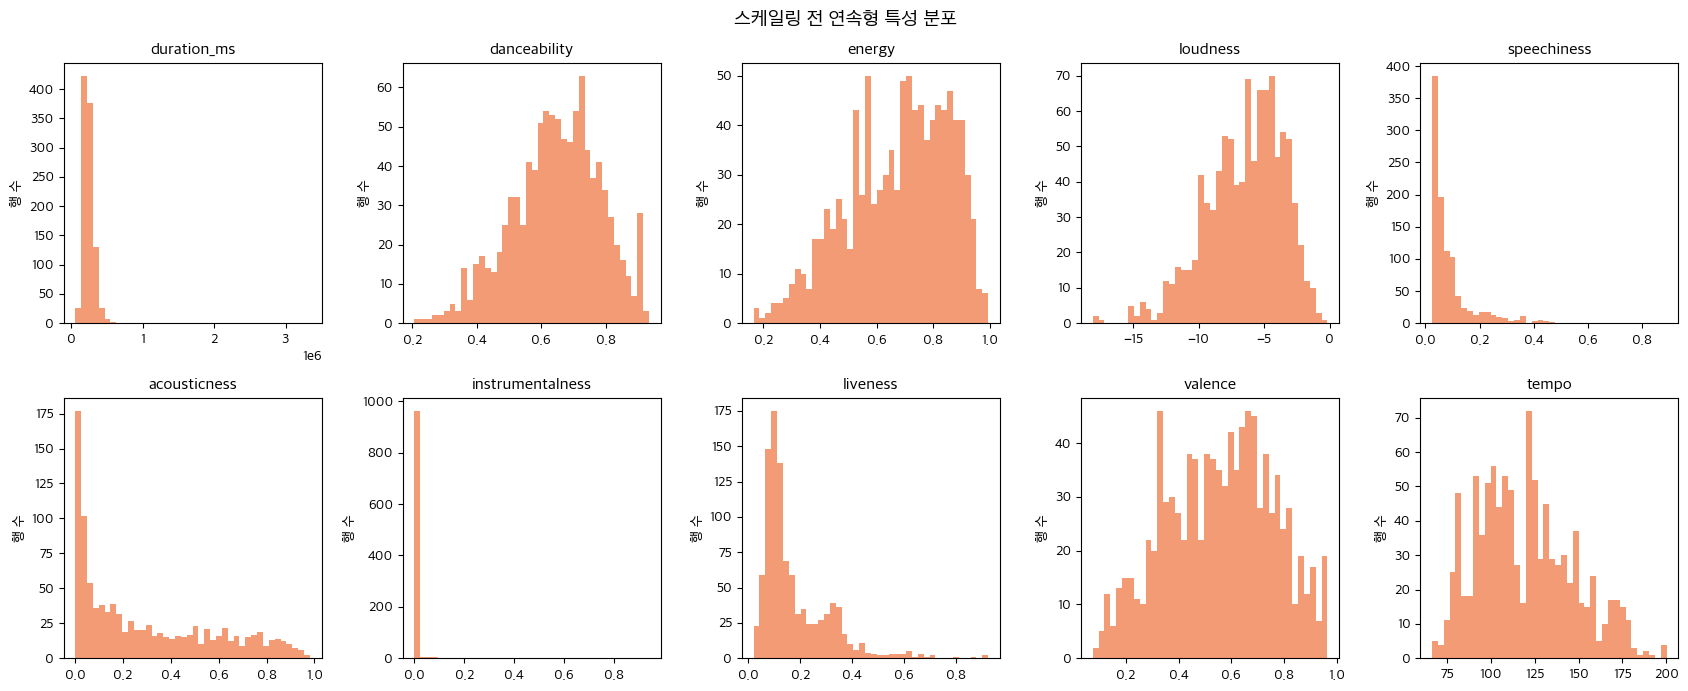

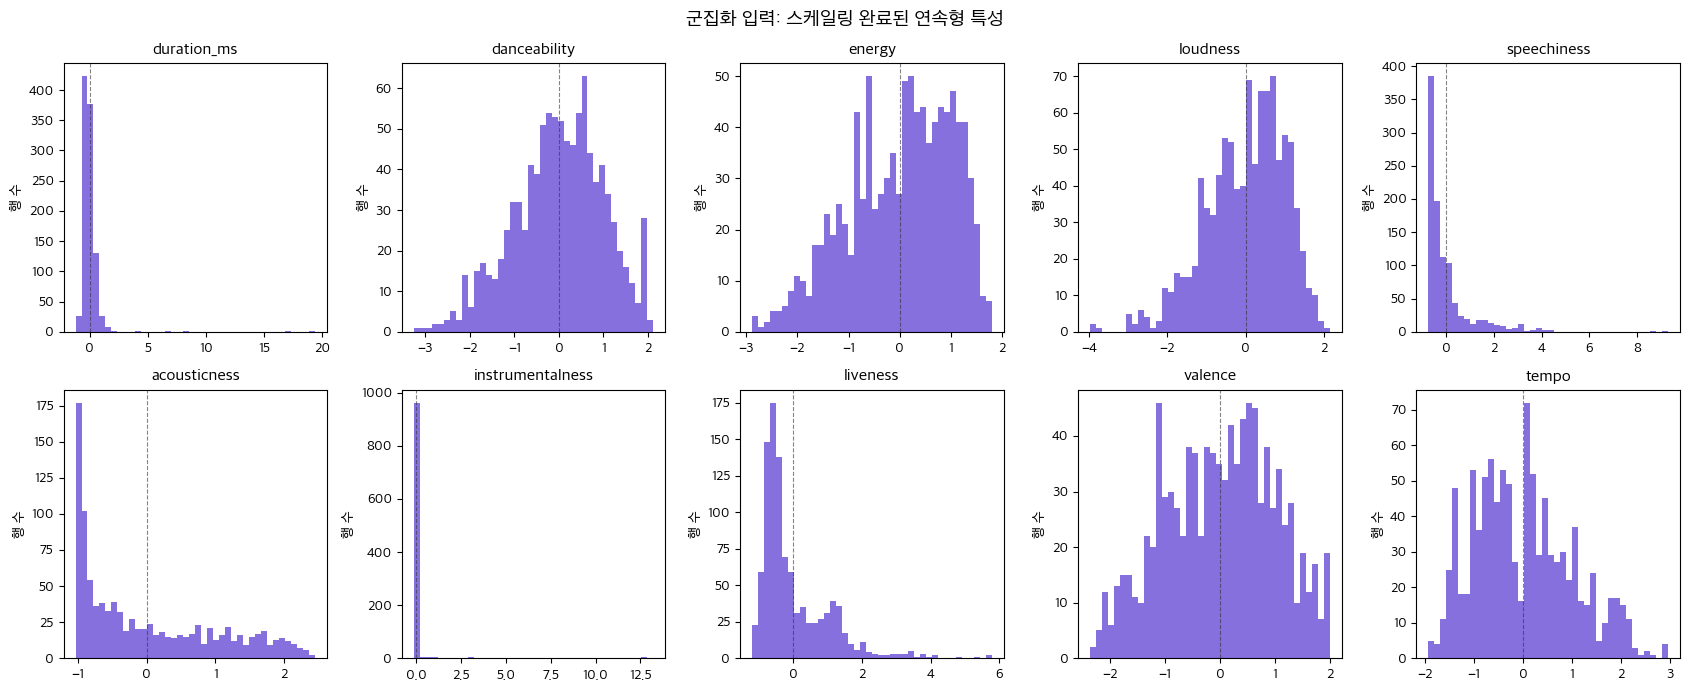

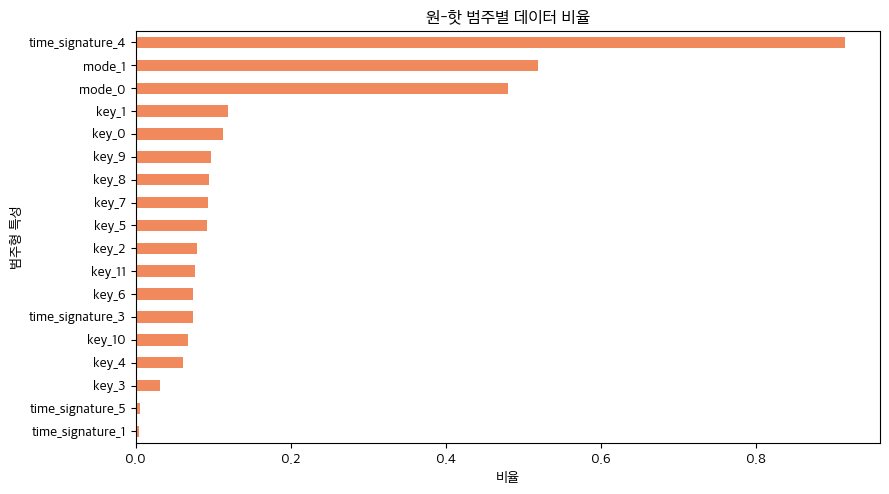

,count,mean,std,min,25%,50%,75%,max
duration_ms,998.0,0.0,1.001,-1.213,-0.350,-0.138,0.198,19.432
danceability,998.0,-0.0,1.001,-3.264,-0.633,0.061,0.682,2.123
energy,998.0,-0.0,1.001,-2.892,-0.717,0.145,0.806,1.799
loudness,998.0,0.0,1.001,-3.971,-0.636,0.113,0.737,2.154
speechiness,998.0,0.0,1.001,-0.744,-0.587,-0.362,0.163,9.293
acousticness,998.0,-0.0,1.001,-1.040,-0.907,-0.378,0.777,2.455
instrumentalness,998.0,0.0,1.001,-0.140,-0.140,-0.140,-0.138,13.227
liveness,998.0,-0.0,1.001,-1.209,-0.657,-0.402,0.445,5.774
valence,998.0,0.0,1.001,-2.367,-0.775,0.066,0.739,2.004
tempo,998.0,-0.0,1.001,-1.933,-0.775,-0.088,0.685,2.960


In [103]:
print(f"최종 모델 입력 크기: {X.shape}  |  duration 버전: {DURATION_VERSION}")
print(f"연속형 특성 평균 범위: {X[continuous_model_cols].mean().min():.3f} ~ {X[continuous_model_cols].mean().max():.3f}")
print(f"연속형 특성 표준편차 범위: {X[continuous_model_cols].std().min():.3f} ~ {X[continuous_model_cols].std().max():.3f}")

fig, axes = plt.subplots(2, 5, figsize=(17, 7))
for ax, column in zip(axes.flat, continuous_model_cols):
    ax.hist(model_continuous[column], bins=40, color="#f08a5d", alpha=0.85)
    ax.set_title(column)
    ax.set_ylabel("행 수")
fig.suptitle("스케일링 전 연속형 특성 분포", fontsize=14)
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(2, 5, figsize=(17, 7))
for ax, column in zip(axes.flat, continuous_model_cols):
    ax.hist(X[column], bins=40, color="#7057d9", alpha=0.85)
    ax.set_title(column)
    ax.set_ylabel("행 수")
    ax.axvline(0, color="#333333", linestyle="--", linewidth=0.8, alpha=0.6)
fig.suptitle("군집화 입력: 스케일링 완료된 연속형 특성", fontsize=14)
plt.tight_layout()
plt.show()

categorical_prevalence = X[X_categorical.columns].mean().sort_values()
ax = categorical_prevalence.plot(
    kind="barh", figsize=(9, max(4, len(categorical_prevalence) * 0.28)),
    color="#f08a5d"
)
ax.set_title("원-핫 범주별 데이터 비율")
ax.set_xlabel("비율")
ax.set_ylabel("범주형 특성")
plt.tight_layout()
plt.show()

display(X[continuous_model_cols].describe().T.round(3))

## 4. 베이스라인: K-Means

test1과 비교할 수 있도록 우선 K=6을 임시 기준으로 둡니다. 이 값이 최종 정답이라는 뜻은 아닙니다. 뒤의 여러 K와 다른 알고리즘의 결과를 보고 선택합니다.

In [104]:
# 모든 알고리즘을 같은 재현 가능한 표본에서 비교합니다.
MODEL_SAMPLE_SIZE = 1500
X_compare = X.sample(
    n=min(MODEL_SAMPLE_SIZE, len(X)),
    random_state=RANDOM_STATE,
)
X_compare_array = X_compare.to_numpy(dtype=np.float32)
df_compare = df.loc[X_compare.index].copy()

def evaluate_labels(X_values, labels):
    labels = np.asarray(labels)
    noise_mask = labels == -1
    valid_mask = ~noise_mask
    X_valid = X_values[valid_mask]
    labels_valid = labels[valid_mask]
    unique_labels = np.unique(labels_valid)
    sizes = pd.Series(labels_valid).value_counts()

    result = {
        "n_clusters": len(unique_labels),
        "noise_rate": float(noise_mask.mean()),
        "smallest_cluster": int(sizes.min()) if len(sizes) else 0,
        "largest_cluster": int(sizes.max()) if len(sizes) else 0,
        "silhouette": np.nan,
        "davies_bouldin": np.nan,
        "calinski_harabasz": np.nan,
    }
    if 2 <= len(unique_labels) < len(labels_valid):
        result["silhouette"] = silhouette_score(
            X_valid,
            labels_valid,
            sample_size=min(1000, len(labels_valid)),
            random_state=RANDOM_STATE,
        )
        result["davies_bouldin"] = davies_bouldin_score(X_valid, labels_valid)
        result["calinski_harabasz"] = calinski_harabasz_score(X_valid, labels_valid)
    return result

BASELINE_K = 6
with threadpool_limits(limits=4):
    baseline_kmeans = KMeans(
        n_clusters=BASELINE_K,
        n_init=10,
        random_state=RANDOM_STATE,
    )
    baseline_labels = baseline_kmeans.fit_predict(X_compare_array)

baseline_result = evaluate_labels(X_compare_array, baseline_labels)
baseline_result.update({
    "method": "KMeans baseline",
    "parameter": f"K={BASELINE_K}",
    "inertia": baseline_kmeans.inertia_,
})
display(pd.DataFrame([baseline_result]).round(4))
display(pd.Series(baseline_labels, name="cluster").value_counts().sort_index()
        .rename("곡 수").to_frame())

,n_clusters,noise_rate,smallest_cluster,largest_cluster,silhouette,davies_bouldin,calinski_harabasz,method,parameter,inertia
0,6,0.0,2,325,0.1155,1.6347,124.8446,KMeans baseline,K=6,7085.4824


,곡 수
0,93
1,261
2,306
3,11
4,325
5,2


### K-Means 변수별 군집 분리 기여도: duration 원본 vs log1p

군집화에는 정답 라벨이 없으므로 지도학습의 feature importance와 같은 정답형 중요도는 없습니다. 여기서는 K=6으로 두 버전을 각각 군집화하고, 전체 군집 간 제곱합 중 각 원본 변수(원-핫 열은 원래 범주형 변수 단위로 합산)가 차지하는 비율을 비교합니다. 비율이 높으면 그 변수에서 군집 중심들이 더 크게 달라졌다는 뜻입니다. 두 버전은 같은 1,500곡 표본과 같은 나머지 특성·설정을 사용합니다. 이 값은 해당 K-Means 결과를 설명하는 지표이지 인과관계나 보편적인 중요도는 아닙니다.

duration 버전,log1p,raw
변수,,
key,0.22,0.19
mode,0.25,0.13
time_signature,0.24,0.27
tempo,1.08,1.61
valence,7.54,2.45
danceability,6.22,7.96
energy,10.20,10.54
loudness,10.60,9.36
liveness,11.45,4.97


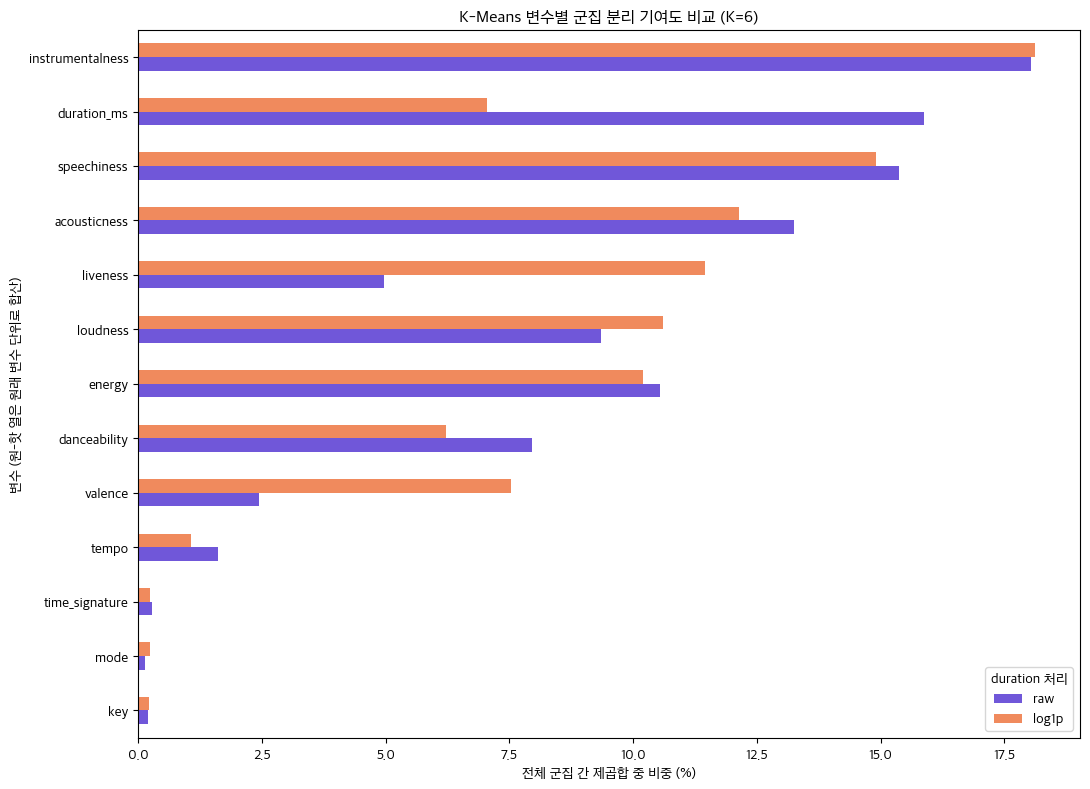

해석: 막대가 클수록 이 표본의 K-Means 군집 중심이 해당 변수에서 더 많이 구분됩니다.


In [105]:
importance_k = BASELINE_K
importance_rows = []
feature_groups = {column: [column] for column in continuous_cols}
for category in ["key", "mode", "time_signature"]:
    feature_groups[category] = [
        column for column in X_categorical.columns
        if column.startswith(f"{category}_")
    ]

for duration_version in ["raw", "log1p"]:
    variant_continuous = df[continuous_cols].copy()
    variant_continuous["duration_ms"] = (
        df["duration_ms"] if duration_version == "raw" else df["duration_log1p"]
    )
    variant_scaled = pd.DataFrame(
        StandardScaler().fit_transform(variant_continuous),
        columns=continuous_cols,
        index=df.index,
    )
    variant_X = pd.concat([variant_scaled, X_categorical], axis=1)
    variant_sample = variant_X.loc[X_compare.index].to_numpy(dtype=np.float32)

    with threadpool_limits(limits=4):
        variant_labels = KMeans(
            n_clusters=importance_k,
            n_init=10,
            random_state=RANDOM_STATE,
        ).fit_predict(variant_sample)

    overall_mean = variant_sample.mean(axis=0)
    between_cluster_ss = np.zeros(variant_sample.shape[1], dtype=float)
    for cluster_id in np.unique(variant_labels):
        cluster_mask = variant_labels == cluster_id
        cluster_values = variant_sample[cluster_mask]
        between_cluster_ss += len(cluster_values) * (
            cluster_values.mean(axis=0) - overall_mean
        ) ** 2

    column_positions = {name: i for i, name in enumerate(variant_X.columns)}
    total_between = between_cluster_ss.sum()
    for feature_name, columns in feature_groups.items():
        positions = [column_positions[column] for column in columns]
        contribution = between_cluster_ss[positions].sum() / total_between * 100
        importance_rows.append({
            "duration 버전": duration_version,
            "변수": feature_name,
            "군집 분리 기여도(%)": contribution,
        })

importance_long = pd.DataFrame(importance_rows)
importance_wide = importance_long.pivot(
    index="변수", columns="duration 버전", values="군집 분리 기여도(%)"
)
plot_order = importance_wide.max(axis=1).sort_values().index
display(importance_wide.loc[plot_order].round(2))

ax = importance_wide.loc[plot_order, ["raw", "log1p"]].plot(
    kind="barh", figsize=(11, 8), color=["#7057d9", "#f08a5d"]
)
ax.set_title(f"K-Means 변수별 군집 분리 기여도 비교 (K={importance_k})")
ax.set_xlabel("전체 군집 간 제곱합 중 비중 (%)")
ax.set_ylabel("변수 (원-핫 열은 원래 변수 단위로 합산)")
ax.legend(title="duration 처리")
plt.tight_layout()
plt.show()

print("해석: 막대가 클수록 이 표본의 K-Means 군집 중심이 해당 변수에서 더 많이 구분됩니다.")

## 5. 다른 군집화 방법과 파라미터 탐색

모든 방법을 같은 표본·같은 특성으로 비교합니다. 지표는 실루엣(클수록 좋음), Davies–Bouldin(작을수록 좋음), Calinski–Harabasz(클수록 좋음), 군집 수와 군집 크기입니다. 지표 하나만으로 자동 선택하지 않습니다.

알고리즘마다 조절하는 값이 다릅니다.

- K-Means: 군집 수 K. inertia의 엘보우와 실루엣 등을 확인합니다.
- GMM: 성분 수. K-Means inertia가 아니라 BIC/AIC를 확인합니다(보통 낮을수록 좋음).
- DBSCAN: 군집 수를 직접 지정하지 않습니다. eps와 min_samples를 조절하고, k-distance와 잡음 비율·군집 크기를 봅니다.
- Mean Shift: 군집 수를 직접 지정하지 않습니다. bandwidth에 따라 결과 군집 수가 달라집니다.
- KNN은 군집화가 아니라 이웃 검색/추천용이므로 여기서 군집 알고리즘 비교 대상으로 취급하지 않습니다.

In [106]:
K_VALUES = range(2, 11)
comparison_rows = []
candidate_labels = {}

with threadpool_limits(limits=4):
    for k in K_VALUES:
        km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE)
        km_labels = km.fit_predict(X_compare_array)
        row = evaluate_labels(X_compare_array, km_labels)
        row.update({
            "method": "KMeans",
            "parameter": f"K={k}",
            "k": k,
            "inertia": km.inertia_,
            "BIC": np.nan,
            "AIC": np.nan,
        })
        comparison_rows.append(row)
        candidate_labels[("KMeans", k)] = km_labels

        gmm = GaussianMixture(
            n_components=k,
            covariance_type="diag",
            n_init=1,
            max_iter=150,
            reg_covar=1e-4,
            random_state=RANDOM_STATE,
        )
        gmm_labels = gmm.fit_predict(X_compare_array)
        row = evaluate_labels(X_compare_array, gmm_labels)
        row.update({
            "method": "GMM",
            "parameter": f"components={k}",
            "k": k,
            "inertia": np.nan,
            "BIC": gmm.bic(X_compare_array),
            "AIC": gmm.aic(X_compare_array),
        })
        comparison_rows.append(row)
        candidate_labels[("GMM", k)] = gmm_labels

comparison_table = pd.DataFrame(comparison_rows)
display(comparison_table.round(4))

,n_clusters,noise_rate,smallest_cluster,largest_cluster,silhouette,davies_bouldin,calinski_harabasz,method,parameter,k,inertia,BIC,AIC
0,2,0.0,358,640,0.2040,1.9747,204.1317,KMeans,K=2,2,9580.5264,NaN,NaN
1,2,0.0,133,865,0.1978,3.3330,45.5249,GMM,components=2,2,NaN,2024.9584,1470.6083
2,3,0.0,110,545,0.1702,1.9939,142.7477,KMeans,K=3,3,8970.2383,NaN,NaN
3,3,0.0,95,582,0.0158,6.1266,26.1848,GMM,components=3,3,NaN,-19975.9228,-20809.9009
4,4,0.0,11,451,0.1385,1.9406,134.2563,KMeans,K=4,4,8215.2500,NaN,NaN
5,4,0.0,72,531,-0.0084,5.3886,21.7739,GMM,components=4,4,NaN,-29798.0447,-30911.6507
6,5,0.0,11,308,0.0997,2.0078,119.8342,KMeans,K=5,5,7785.7622,NaN,NaN
7,5,0.0,32,498,0.0006,5.3458,21.6473,GMM,components=5,5,NaN,-38957.7941,-40351.0280
8,6,0.0,2,325,0.1155,1.6347,124.8446,KMeans,K=6,6,7085.4824,NaN,NaN
9,6,0.0,34,398,-0.0114,5.4037,20.2797,GMM,components=6,6,NaN,-43067.4003,-44740.2621


In [107]:
# DBSCAN은 eps를 k-nearest-neighbor 거리 분포에서 후보로 정합니다.
dbscan_rows = []
k_distance_curves = {}
EPS_QUANTILES = [0.90, 0.95, 0.98, 0.99]
MIN_SAMPLES_VALUES = [10, 20]

for min_samples in MIN_SAMPLES_VALUES:
    neighbors = NearestNeighbors(n_neighbors=min_samples + 1, n_jobs=-1)
    neighbors.fit(X_compare_array)
    distances, _ = neighbors.kneighbors(X_compare_array)
    k_distances = np.sort(distances[:, -1])
    k_distance_curves[min_samples] = k_distances
    eps_candidates = np.unique(np.quantile(k_distances, EPS_QUANTILES))

    for eps in eps_candidates:
        model = DBSCAN(eps=float(eps), min_samples=min_samples, n_jobs=-1)
        labels = model.fit_predict(X_compare_array)
        row = evaluate_labels(X_compare_array, labels)
        row.update({
            "method": "DBSCAN",
            "parameter": f"eps={eps:.4f}, min_samples={min_samples}",
            "eps": float(eps),
            "min_samples": min_samples,
        })
        dbscan_rows.append(row)
        candidate_labels[("DBSCAN", float(eps), min_samples)] = labels

dbscan_table = pd.DataFrame(dbscan_rows)
display(dbscan_table.round(4))

,n_clusters,noise_rate,smallest_cluster,largest_cluster,silhouette,davies_bouldin,calinski_harabasz,method,parameter,eps,min_samples
0,1,0.0381,960,960,NaN,NaN,NaN,DBSCAN,"eps=2.9381, min_samples=10",2.9381,10
1,1,0.0230,975,975,NaN,NaN,NaN,DBSCAN,"eps=3.2603, min_samples=10",3.2603,10
2,1,0.0120,986,986,NaN,NaN,NaN,DBSCAN,"eps=4.6661, min_samples=10",4.6661,10
3,1,0.0080,990,990,NaN,NaN,NaN,DBSCAN,"eps=6.4556, min_samples=10",6.4556,10
4,1,0.0251,973,973,NaN,NaN,NaN,DBSCAN,"eps=3.2381, min_samples=20",3.2381,20
5,1,0.0230,975,975,NaN,NaN,NaN,DBSCAN,"eps=3.5095, min_samples=20",3.5095,20
6,1,0.0120,986,986,NaN,NaN,NaN,DBSCAN,"eps=4.8781, min_samples=20",4.8781,20
7,1,0.0050,993,993,NaN,NaN,NaN,DBSCAN,"eps=7.3964, min_samples=20",7.3964,20


In [108]:
# Mean Shift의 bandwidth 후보를 여러 분위수에서 추정해 비교합니다.
meanshift_rows = []
meanshift_bandwidths = {}

for quantile in [0.10, 0.15, 0.20]:
    bandwidth = estimate_bandwidth(
        X_compare_array,
        quantile=quantile,
        n_samples=min(500, len(X_compare_array)),
        random_state=RANDOM_STATE,
        n_jobs=-1,
    )
    if not np.isfinite(bandwidth) or bandwidth <= 0:
        print(f"quantile={quantile}: 유효하지 않은 bandwidth({bandwidth}), 건너뜁니다.")
        continue

    model = MeanShift(
        bandwidth=bandwidth,
        bin_seeding=True,
        n_jobs=-1,
    )
    labels = model.fit_predict(X_compare_array)
    row = evaluate_labels(X_compare_array, labels)
    row.update({
        "method": "MeanShift",
        "parameter": f"quantile={quantile}, bandwidth={bandwidth:.4f}",
        "quantile": quantile,
        "bandwidth": float(bandwidth),
    })
    meanshift_rows.append(row)
    meanshift_bandwidths[quantile] = float(bandwidth)
    candidate_labels[("MeanShift", float(bandwidth))] = labels

meanshift_table = pd.DataFrame(meanshift_rows)
display(meanshift_table.round(4))

,n_clusters,noise_rate,smallest_cluster,largest_cluster,silhouette,davies_bouldin,calinski_harabasz,method,parameter,quantile,bandwidth
0,10,0.0,1,953,0.1944,1.0476,29.9428,MeanShift,"quantile=0.1, bandwidth=3.1973",0.10,3.1973
1,8,0.0,1,962,0.2888,0.9754,34.5820,MeanShift,"quantile=0.15, bandwidth=3.3972",0.15,3.3972
2,6,0.0,2,976,0.3741,0.8183,42.1407,MeanShift,"quantile=0.2, bandwidth=3.5552",0.20,3.5552


## 6. 파라미터 곡선과 최종 모델 선택

K-Means에는 inertia 엘보우, GMM에는 BIC/AIC, 밀도 기반 방법에는 거리·잡음·군집 수 곡선을 확인합니다. “모든 모델의 엘보우”를 억지로 그리는 대신, 각 모델의 의미 있는 선택 기준을 사용합니다.

최종 선택에서는 군집 품질 지표뿐 아니라 너무 작은 군집이 생기는지, 잡음이 과도한지, 실제 곡 추천에 적용할 때 새 곡을 배정할 수 있는지도 함께 고려합니다.

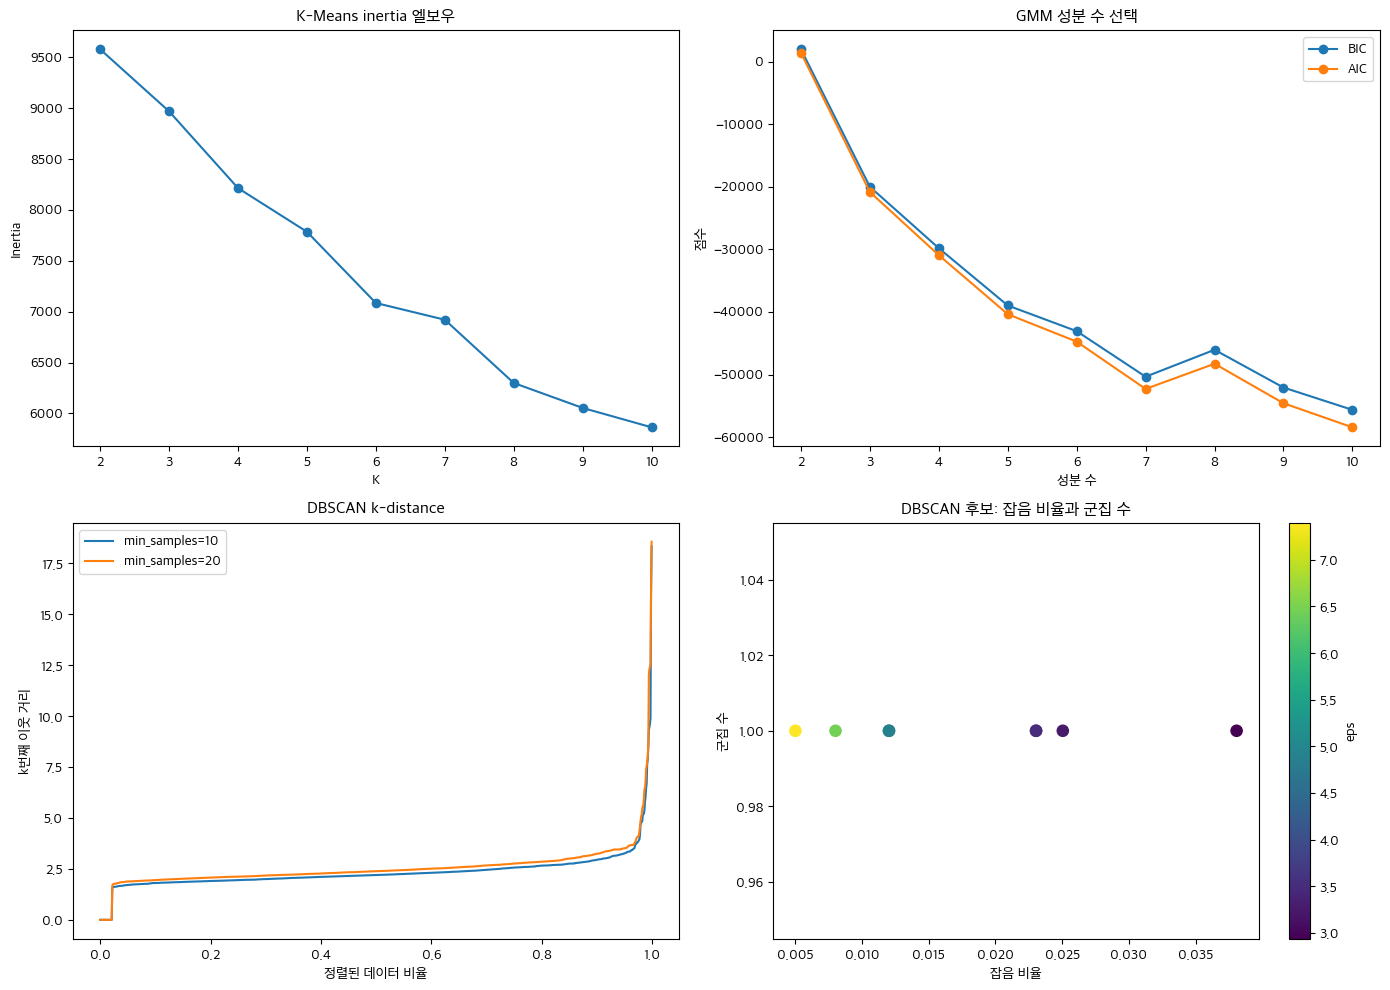

K-Means / GMM 비교표


,method,parameter,n_clusters,silhouette,davies_bouldin,calinski_harabasz,inertia,BIC,AIC
1,GMM,components=2,2,0.1978,3.3330,45.5249,NaN,2024.9584,1470.6083
3,GMM,components=3,3,0.0158,6.1266,26.1848,NaN,-19975.9228,-20809.9009
5,GMM,components=4,4,-0.0084,5.3886,21.7739,NaN,-29798.0447,-30911.6507
7,GMM,components=5,5,0.0006,5.3458,21.6473,NaN,-38957.7941,-40351.0280
9,GMM,components=6,6,-0.0114,5.4037,20.2797,NaN,-43067.4003,-44740.2621
11,GMM,components=7,7,-0.0170,4.7269,19.6446,NaN,-50352.8720,-52305.3618
13,GMM,components=8,8,-0.0356,4.9439,19.5338,NaN,-46046.6419,-48278.7597
15,GMM,components=9,9,-0.0508,4.3986,20.8155,NaN,-52081.3440,-54593.0896
17,GMM,components=10,10,-0.0349,3.8783,24.1599,NaN,-55654.8076,-58446.1812
0,KMeans,K=2,2,0.2040,1.9747,204.1317,9580.5264,NaN,NaN


DBSCAN 후보


,parameter,n_clusters,noise_rate,smallest_cluster,largest_cluster,silhouette
0,"eps=2.9381, min_samples=10",1,0.0381,960,960,NaN
1,"eps=3.2603, min_samples=10",1,0.0230,975,975,NaN
2,"eps=4.6661, min_samples=10",1,0.0120,986,986,NaN
3,"eps=6.4556, min_samples=10",1,0.0080,990,990,NaN
4,"eps=3.2381, min_samples=20",1,0.0251,973,973,NaN
5,"eps=3.5095, min_samples=20",1,0.0230,975,975,NaN
6,"eps=4.8781, min_samples=20",1,0.0120,986,986,NaN
7,"eps=7.3964, min_samples=20",1,0.0050,993,993,NaN


Mean Shift 후보


,parameter,n_clusters,noise_rate,smallest_cluster,largest_cluster,silhouette
0,"quantile=0.1, bandwidth=3.1973",10,0.0,1,953,0.1944
1,"quantile=0.15, bandwidth=3.3972",8,0.0,1,962,0.2888
2,"quantile=0.2, bandwidth=3.5552",6,0.0,2,976,0.3741


In [109]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

km_table = comparison_table[comparison_table["method"] == "KMeans"].sort_values("k")
axes[0, 0].plot(km_table["k"], km_table["inertia"], marker="o")
axes[0, 0].set(title="K-Means inertia 엘보우", xlabel="K", ylabel="Inertia")

gmm_table = comparison_table[comparison_table["method"] == "GMM"].sort_values("k")
axes[0, 1].plot(gmm_table["k"], gmm_table["BIC"], marker="o", label="BIC")
axes[0, 1].plot(gmm_table["k"], gmm_table["AIC"], marker="o", label="AIC")
axes[0, 1].set(title="GMM 성분 수 선택", xlabel="성분 수", ylabel="점수")
axes[0, 1].legend()

for min_samples, curve in k_distance_curves.items():
    axes[1, 0].plot(np.arange(len(curve)) / len(curve), curve,
                    label=f"min_samples={min_samples}")
axes[1, 0].set(title="DBSCAN k-distance", xlabel="정렬된 데이터 비율",
               ylabel="k번째 이웃 거리")
axes[1, 0].legend()

if len(dbscan_table):
    db_curve = dbscan_table.groupby("min_samples").agg(
        eps=("eps", "mean"),
        noise_rate=("noise_rate", "mean"),
        n_clusters=("n_clusters", "mean"),
    )
    axes[1, 1].scatter(dbscan_table["noise_rate"], dbscan_table["n_clusters"],
                       c=dbscan_table["eps"], cmap="viridis", s=65)
    axes[1, 1].set(title="DBSCAN 후보: 잡음 비율과 군집 수",
                   xlabel="잡음 비율", ylabel="군집 수")
    plt.colorbar(axes[1, 1].collections[0], ax=axes[1, 1], label="eps")
else:
    axes[1, 1].set_visible(False)

plt.tight_layout()
plt.show()

print("K-Means / GMM 비교표")
display(comparison_table.sort_values(
    ["method", "k"]
)[["method", "parameter", "n_clusters", "silhouette",
   "davies_bouldin", "calinski_harabasz", "inertia", "BIC", "AIC"]].round(4))

print("DBSCAN 후보")
display(dbscan_table[["parameter", "n_clusters", "noise_rate",
                      "smallest_cluster", "largest_cluster", "silhouette"]].round(4))

print("Mean Shift 후보")
display(meanshift_table[["parameter", "n_clusters", "noise_rate",
                         "smallest_cluster", "largest_cluster",
                         "silhouette"]].round(4))

### K-Means 군집 수별 실루엣 분석 및 PCA 시각화

K=2~10 각각의 실루엣 계수 분포와 평균 점수를 비교하고, 같은 비교 표본의 군집을 PCA 2차원 산점도로 나란히 확인합니다. PCA는 눈으로 보기 위한 투영이며, K-Means 학습은 스케일링된 전체 특성 공간에서 수행합니다. 계산과 시각화는 알고리즘 비교에 사용한 동일 표본(최대 1,500곡)을 사용합니다.

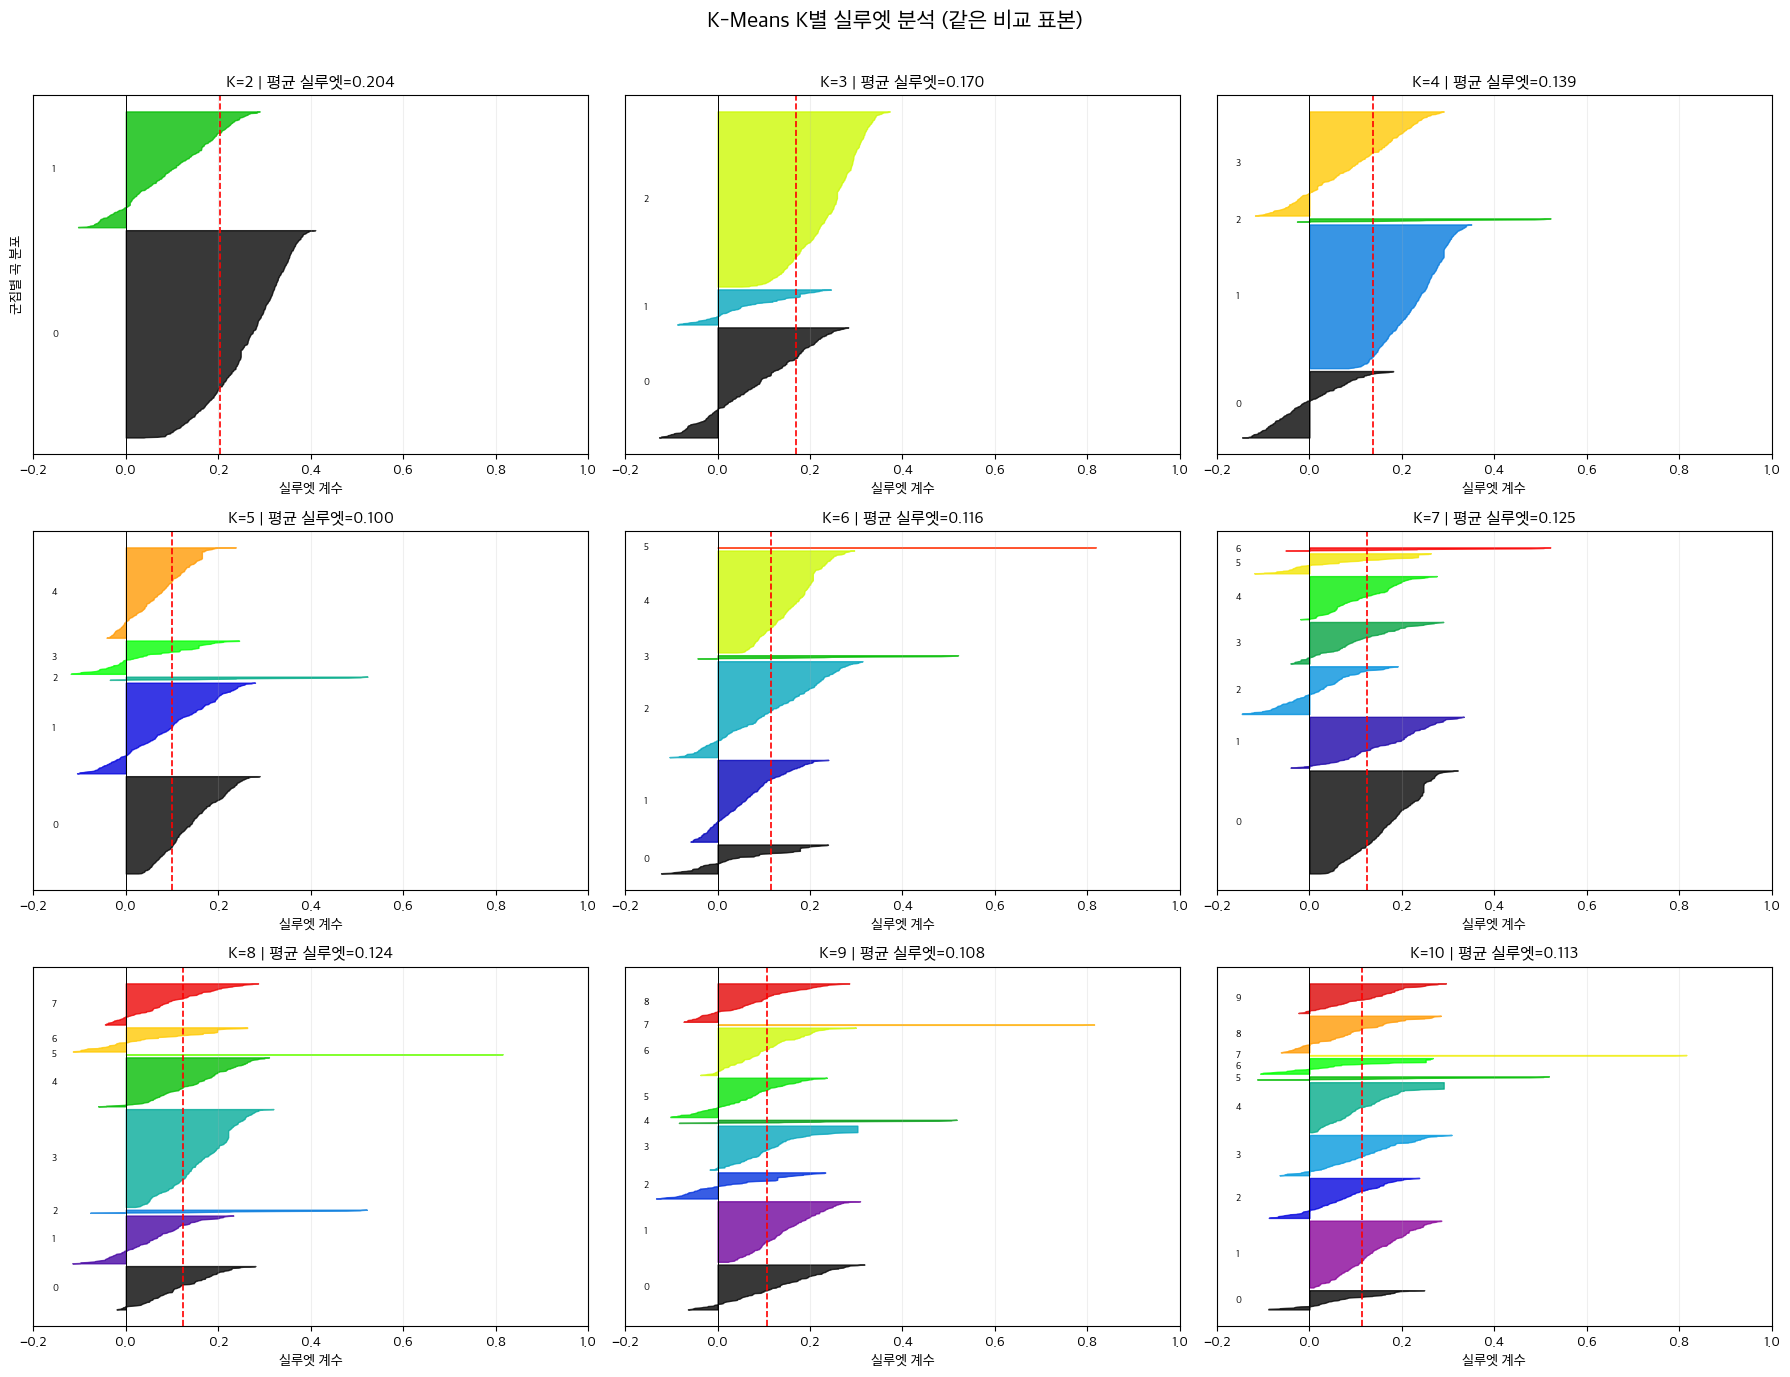

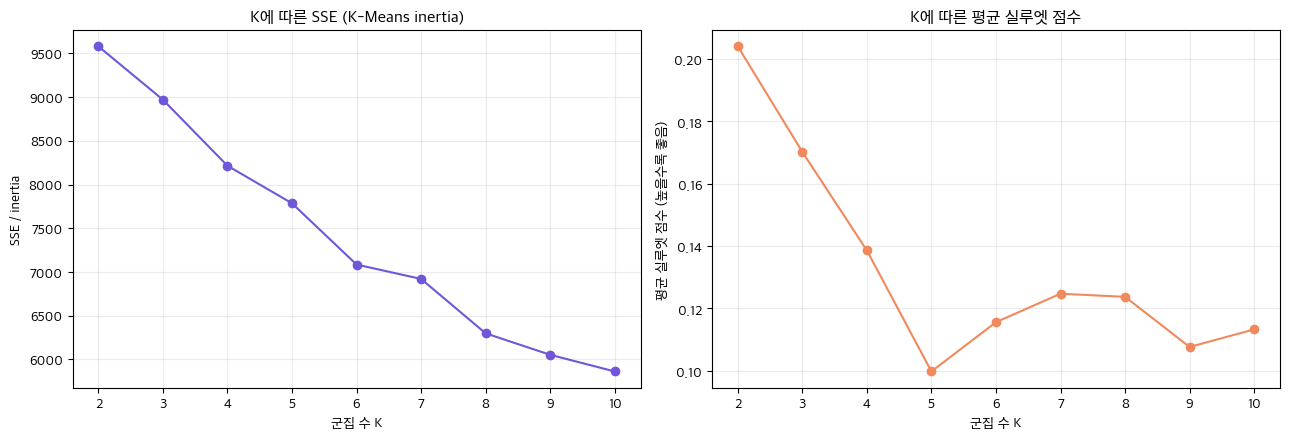

SSE는 K가 늘면 보통 감소합니다. 최솟값보다 감소 폭이 완만해지는 엘보우 지점을 확인하세요.


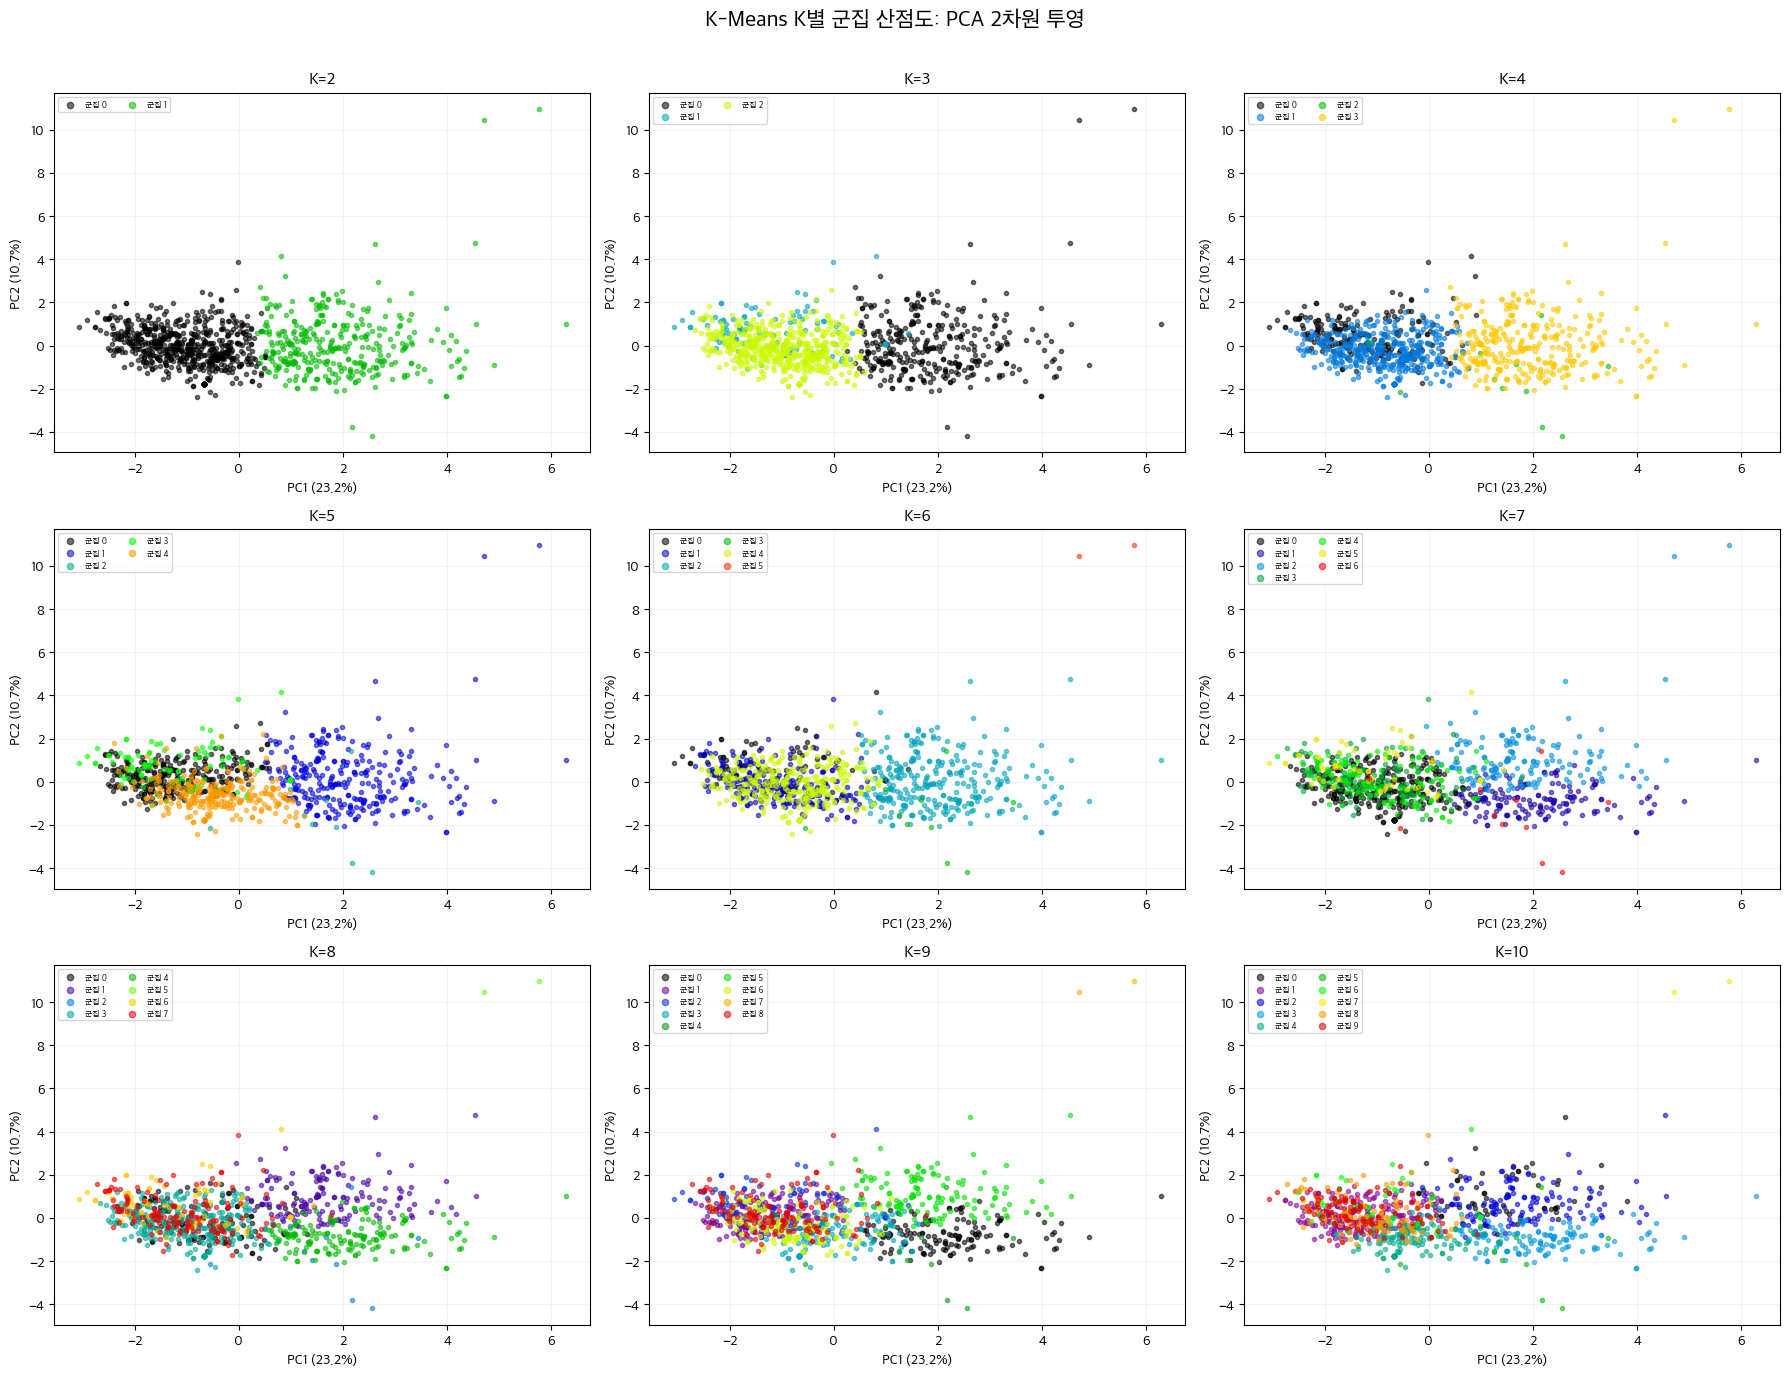

참고: 산점도는 PCA로 축약한 시각화이며, 실제 K-Means 군집은 전체 특성 공간에서 계산했습니다.


In [110]:
KMEANS_VIS_K_VALUES = range(2, 11)
silhouette_mean_rows = []

# 위에서 같은 표본으로 학습한 K-Means 결과(candidate_labels)를 재사용합니다.
fig, axes = plt.subplots(3, 3, figsize=(18, 14))
for ax, k in zip(axes.flat, KMEANS_VIS_K_VALUES):
    labels = candidate_labels[("KMeans", k)]
    sample_silhouette_values = silhouette_samples(X_compare_array, labels)
    average_silhouette = sample_silhouette_values.mean()
    silhouette_mean_rows.append({"k": k, "mean_silhouette": average_silhouette})

    y_lower = 10
    for cluster_id in range(k):
        cluster_values = np.sort(sample_silhouette_values[labels == cluster_id])
        cluster_size = len(cluster_values)
        y_upper = y_lower + cluster_size
        color = plt.cm.nipy_spectral(cluster_id / max(k, 1))
        ax.fill_betweenx(
            np.arange(y_lower, y_upper), 0, cluster_values,
            facecolor=color, edgecolor=color, alpha=0.78
        )
        ax.text(-0.16, y_lower + 0.5 * cluster_size, str(cluster_id),
                fontsize=7, va="center")
        y_lower = y_upper + 8

    ax.axvline(average_silhouette, color="red", linestyle="--", linewidth=1.2)
    ax.axvline(0, color="black", linewidth=0.7)
    ax.set_xlim(-0.2, 1.0)
    ax.set_title(f"K={k} | 평균 실루엣={average_silhouette:.3f}")
    ax.set_xlabel("실루엣 계수")
    ax.set_yticks([])
    ax.grid(axis="x", alpha=0.2)
axes[0, 0].set_ylabel("군집별 곡 분포")
fig.suptitle("K-Means K별 실루엣 분석 (같은 비교 표본)", fontsize=16)
plt.tight_layout(rect=[0, 0, 1, 0.97])
plt.show()

# Inertia는 K-Means의 SSE(군집 내 제곱거리 합)입니다. 같은 표본에서
# K가 늘어날 때 SSE와 평균 실루엣 점수가 어떻게 변하는지 함께 확인합니다.
km_summary = comparison_table[comparison_table["method"] == "KMeans"].sort_values("k")
silhouette_summary = pd.DataFrame(silhouette_mean_rows)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(km_summary["k"], km_summary["inertia"], marker="o", color="#7057d9")
axes[0].set_title("K에 따른 SSE (K-Means inertia)")
axes[0].set_xlabel("군집 수 K")
axes[0].set_ylabel("SSE / inertia")
axes[0].set_xticks(list(KMEANS_VIS_K_VALUES))
axes[0].grid(alpha=0.25)
axes[1].plot(silhouette_summary["k"], silhouette_summary["mean_silhouette"],
             marker="o", color="#f08a5d")
axes[1].set_title("K에 따른 평균 실루엣 점수")
axes[1].set_xlabel("군집 수 K")
axes[1].set_ylabel("평균 실루엣 점수 (높을수록 좋음)")
axes[1].set_xticks(list(KMEANS_VIS_K_VALUES))
axes[1].grid(alpha=0.25)
plt.tight_layout()
plt.show()
print("SSE는 K가 늘면 보통 감소합니다. 최솟값보다 감소 폭이 완만해지는 엘보우 지점을 확인하세요.")

# PCA는 K별 군집 결과를 같은 좌표계에서 눈으로 비교하기 위한 2차원 투영입니다.
pca_2d = PCA(n_components=2, random_state=RANDOM_STATE)
X_compare_2d = pca_2d.fit_transform(X_compare_array)
fig, axes = plt.subplots(3, 3, figsize=(18, 14))
for ax, k in zip(axes.flat, KMEANS_VIS_K_VALUES):
    labels = candidate_labels[("KMeans", k)]
    colors = plt.cm.nipy_spectral(np.linspace(0, 1, k, endpoint=False))
    for cluster_id, color in enumerate(colors):
        mask = labels == cluster_id
        ax.scatter(
            X_compare_2d[mask, 0], X_compare_2d[mask, 1],
            s=9, alpha=0.55, color=color, label=f"군집 {cluster_id}"
        )
    ax.set_title(f"K={k}")
    ax.set_xlabel(f"PC1 ({pca_2d.explained_variance_ratio_[0]:.1%})")
    ax.set_ylabel(f"PC2 ({pca_2d.explained_variance_ratio_[1]:.1%})")
    ax.legend(fontsize=6, markerscale=1.5, ncol=2, loc="best")
    ax.grid(alpha=0.15)
fig.suptitle("K-Means K별 군집 산점도: PCA 2차원 투영", fontsize=16)
plt.tight_layout(rect=[0, 0, 1, 0.97])
plt.show()
print("참고: 산점도는 PCA로 축약한 시각화이며, 실제 K-Means 군집은 전체 특성 공간에서 계산했습니다.")

### 선택할 모델 지정

K=3 결과에서는 두 곡만 별도 군집으로 분리되어 해석과 추천에 유용한 소규모 군집이 되지 못했습니다. 현재는 군집 크기와 해석 가능성을 고려해 K=2를 선택했습니다. K-Means/GMM은 전체 곡에 군집을 예측할 수 있습니다. DBSCAN/Mean Shift는 기본 구현에 새 데이터의 `predict`가 없으므로 여기서는 공정 비교에 쓴 표본에서 최종 결과를 해석합니다. 웹 앱에 적용할 경우 별도의 신규 곡 배정 규칙이 필요합니다. 설정을 변경하면 이 셀부터 마지막 웹 내보내기 셀까지 다시 실행하세요.

In [111]:
FINAL_METHOD = "KMeans"  # "KMeans", "GMM", "DBSCAN", "MeanShift"
FINAL_N_CLUSTERS = 2       # K-Means 또는 GMM 선택 시 사용
FINAL_DBSCAN_EPS = None    # DBSCAN 선택 시 비교표의 eps 값을 입력
FINAL_DBSCAN_MIN_SAMPLES = 10
FINAL_MEANSHIFT_BANDWIDTH = None  # MeanShift 선택 시 비교표의 bandwidth 입력

if FINAL_METHOD == "KMeans":
    final_model = KMeans(
        n_clusters=FINAL_N_CLUSTERS,
        n_init=10,
        random_state=RANDOM_STATE,
    )
    with threadpool_limits(limits=4):
        final_labels = final_model.fit_predict(X.to_numpy(dtype=np.float32))
    df_final = df.copy()

elif FINAL_METHOD == "GMM":
    final_model = GaussianMixture(
        n_components=FINAL_N_CLUSTERS,
        covariance_type="diag",
        n_init=1,
        max_iter=150,
        reg_covar=1e-4,
        random_state=RANDOM_STATE,
    )
    with threadpool_limits(limits=4):
        final_labels = final_model.fit_predict(X.to_numpy(dtype=np.float32))
    df_final = df.copy()

elif FINAL_METHOD == "DBSCAN":
    if FINAL_DBSCAN_EPS is None:
        raise ValueError("DBSCAN 결과표를 보고 FINAL_DBSCAN_EPS를 지정해 주세요.")
    final_model = DBSCAN(
        eps=FINAL_DBSCAN_EPS,
        min_samples=FINAL_DBSCAN_MIN_SAMPLES,
        n_jobs=-1,
    )
    final_labels = final_model.fit_predict(X_compare_array)
    df_final = df_compare.copy()

elif FINAL_METHOD == "MeanShift":
    if FINAL_MEANSHIFT_BANDWIDTH is None:
        raise ValueError("Mean Shift 결과표를 보고 FINAL_MEANSHIFT_BANDWIDTH를 지정해 주세요.")
    final_model = MeanShift(
        bandwidth=FINAL_MEANSHIFT_BANDWIDTH,
        bin_seeding=True,
        n_jobs=-1,
    )
    final_labels = final_model.fit_predict(X_compare_array)
    df_final = df_compare.copy()

else:
    raise ValueError("FINAL_METHOD 값이 지원되는 방법과 일치하지 않습니다.")

df_final = df_final.copy()
df_final["cluster"] = np.asarray(final_labels)
print(f"최종 방법: {FINAL_METHOD}")
print(f"최종 결과 분석 행 수: {len(df_final):,}")
display(df_final["cluster"].value_counts().sort_index().rename("곡 수").to_frame())

최종 방법: KMeans
최종 결과 분석 행 수: 998


,곡 수
0,358
1,640


### 군집 내 유사곡 추천: 웹의 KNN 방식

K-Means는 곡마다 군집 라벨을 붙이고, 추천 단계는 선택한 곡과 **같은 군집에 속한 곡만** 후보로 둡니다. 후보의 10개 연속형 오디오 특성을 표준화하고 key·mode·time_signature 원-핫 값을 합친 뒤 코사인 거리를 계산해 가장 가까운 5곡을 보여줍니다. popularity와 제목·가수 같은 메타데이터는 거리 계산에 넣지 않습니다.

아래 셀은 실제 최종 군집 결과에서 기준 곡 하나를 정해 이 절차를 재현합니다. 웹 앱은 브라우저에서 정규화한 벡터의 내적으로 코사인 유사도를 직접 계산하고, 이 셀은 같은 수학적 기준을 scikit-learn의 NearestNeighbors로 보여줍니다. 따라서 KNN은 군집화 모델이 아니라 **군집 안에서 이웃 곡을 검색하는 추천 단계**입니다. 슬라이더 추천도 같은 군집과 특성 공간을 사용하되, 기준 벡터의 일부 오디오 값을 바꿔 검색합니다.


기준 곡: Ko Ko Bop - EXO | K-Means 군집 1
같은 군집에서 검색 가능한 후보: 558곡


,순위,곡 제목,가수,군집,코사인 유사도,코사인 거리
0,1,Dance The Night Away,TWICE,1,0.8678,0.1322
1,2,DOMINO,Stray Kids,1,0.8470,0.1530
2,3,After LIKE,IVE,1,0.8329,0.1671
3,4,Airplane pt.2,BTS,1,0.8328,0.1672
4,5,Outro : Ego,BTS,1,0.8322,0.1678


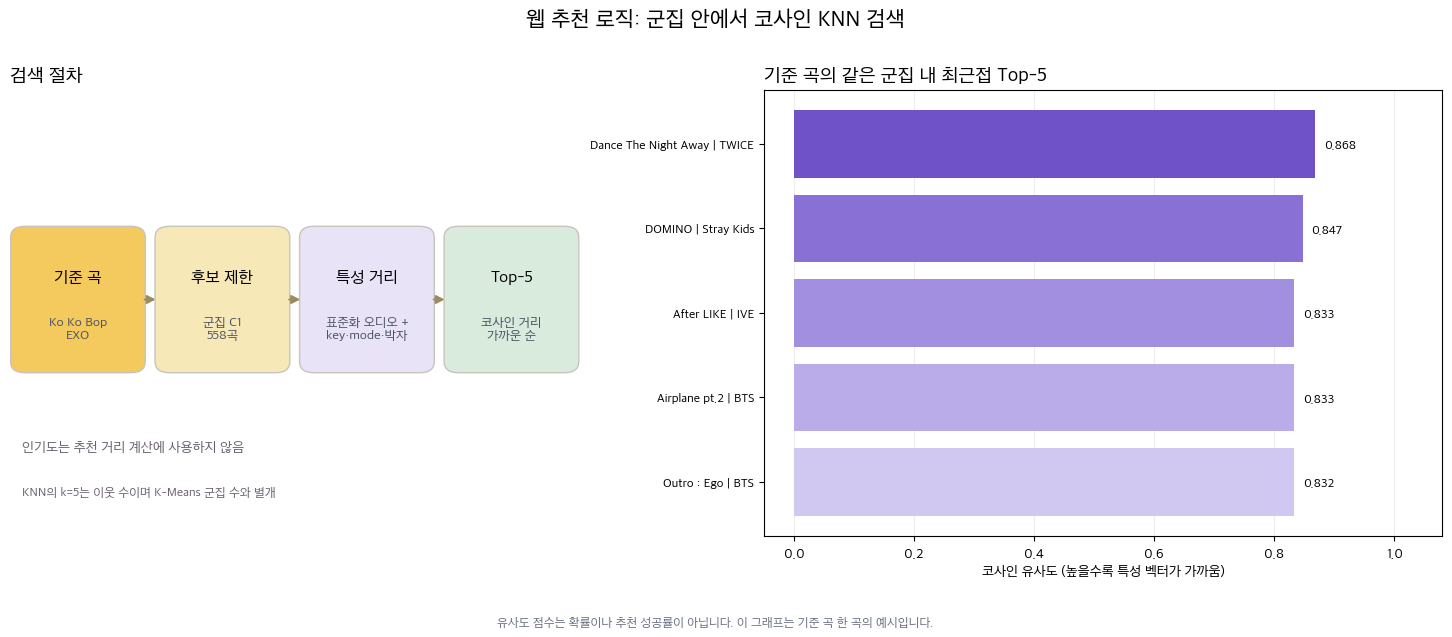

In [112]:
if FINAL_METHOD != "KMeans":
    raise ValueError("현재 웹 추천 흐름은 최종 K-Means 군집 라벨을 사용합니다.")

if not df_final.index.isin(X.index).all():
    raise ValueError("df_final과 X의 행 인덱스가 맞지 않습니다. 위 셀부터 다시 실행하세요.")
if "track_name" not in df_final.columns or "artists" not in df_final.columns:
    raise KeyError("곡 제목(track_name) 또는 가수(artists) 열이 없습니다.")

# K-Means와 동일한 입력 특성 공간을 가져와 각 행의 길이를 1로 맞춥니다.
# 이때 두 벡터의 내적은 코사인 유사도와 같습니다.
knn_metadata = df_final.copy()
knn_matrix = X.loc[knn_metadata.index].to_numpy(dtype=np.float32)
knn_norms = np.linalg.norm(knn_matrix, axis=1, keepdims=True)
knn_vectors = knn_matrix / np.maximum(knn_norms, 1e-12)

knn_titles = knn_metadata["track_name"].fillna("").astype(str).str.strip().to_numpy()
knn_artists = knn_metadata["artists"].fillna("").astype(str).str.strip().to_numpy()
knn_clusters = knn_metadata["cluster"].to_numpy()

# 제목·가수 정보가 있는 곡 중 가장 큰 군집에서 재현 가능한 기준 곡을 고릅니다.
knn_valid_positions = np.flatnonzero((knn_titles != "") & (knn_artists != ""))
knn_cluster_sizes = (
    knn_metadata.iloc[knn_valid_positions]
    .groupby("cluster")
    .size()
    .sort_values(ascending=False)
)
knn_query_cluster = knn_cluster_sizes.index[0]
knn_cluster_positions = knn_valid_positions[
    knn_clusters[knn_valid_positions] == knn_query_cluster
]
knn_seed_position = knn_cluster_positions[len(knn_cluster_positions) // 2]

# 웹 앱과 같이 자기 자신과 같은 제목·가수의 중복 곡은 후보에서 뺍니다.
knn_seed_identity = (
    knn_titles[knn_seed_position].casefold(),
    knn_artists[knn_seed_position].casefold(),
)
knn_seen = {knn_seed_identity}
knn_candidate_positions = []
for position in knn_cluster_positions:
    if position == knn_seed_position:
        continue
    identity = (knn_titles[position].casefold(), knn_artists[position].casefold())
    if identity in knn_seen:
        continue
    knn_seen.add(identity)
    knn_candidate_positions.append(position)

if not knn_candidate_positions:
    raise ValueError("기준 곡과 같은 군집에서 추천 후보를 찾지 못했습니다.")

knn_k = min(5, len(knn_candidate_positions))
knn_search = NearestNeighbors(
    n_neighbors=knn_k,
    metric="cosine",
    algorithm="brute",
)
knn_candidate_vectors = knn_vectors[knn_candidate_positions]
knn_search.fit(knn_candidate_vectors)
knn_distances, knn_local_indices = knn_search.kneighbors(
    knn_vectors[knn_seed_position].reshape(1, -1)
)

knn_result_rows = []
for rank, (distance, local_index) in enumerate(
    zip(knn_distances[0], knn_local_indices[0]), start=1
):
    position = knn_candidate_positions[local_index]
    knn_result_rows.append({
        "순위": rank,
        "곡 제목": knn_titles[position],
        "가수": knn_artists[position],
        "군집": int(knn_clusters[position]),
        "코사인 유사도": float(np.clip(1 - distance, -1, 1)),
        "코사인 거리": float(distance),
    })
knn_recommendations = pd.DataFrame(knn_result_rows)

print(
    f"기준 곡: {knn_titles[knn_seed_position]} - {knn_artists[knn_seed_position]}"
    f" | K-Means 군집 {knn_query_cluster}"
)
print(f"같은 군집에서 검색 가능한 후보: {len(knn_candidate_positions):,}곡")
display(knn_recommendations.round({"코사인 유사도": 4, "코사인 거리": 4}))

# 한 그림에서 추천 절차와 실제 Top-5 검색 결과를 함께 확인합니다.
from matplotlib.patches import FancyArrowPatch, FancyBboxPatch

fig = plt.figure(figsize=(15, 6.2))
grid = fig.add_gridspec(1, 2, width_ratios=[1.15, 1.35], wspace=0.28)
ax_flow = fig.add_subplot(grid[0, 0])
ax_rank = fig.add_subplot(grid[0, 1])

ax_flow.set_title("검색 절차", loc="left", fontsize=14, fontweight="bold")
ax_flow.set_xlim(0, 1)
ax_flow.set_ylim(0, 1)
ax_flow.axis("off")
knn_flow_title = knn_titles[knn_seed_position]
knn_flow_artist = knn_artists[knn_seed_position]
if len(knn_flow_title) > 13:
    knn_flow_title = knn_flow_title[:12] + "…"
if len(knn_flow_artist) > 13:
    knn_flow_artist = knn_flow_artist[:12] + "…"
flow_steps = [
    ("기준 곡", f"{knn_flow_title}\n{knn_flow_artist}", "#F4C95D"),
    ("후보 제한", f"군집 C{knn_query_cluster}\n{len(knn_candidate_positions):,}곡", "#F6E8B7"),
    ("특성 거리", "표준화 오디오 +\nkey·mode·박자", "#E9E3F8"),
    ("Top-5", "코사인 거리\n가까운 순", "#D9EBDD"),
]
flow_x = [0.015, 0.265, 0.515, 0.765]
box_width = 0.205
for index, ((heading, detail, color), x_pos) in enumerate(zip(flow_steps, flow_x)):
    box = FancyBboxPatch(
        (x_pos, 0.38), box_width, 0.30,
        boxstyle="round,pad=0.014,rounding_size=0.025",
        facecolor=color, edgecolor="#C8C4BC", linewidth=1.0,
    )
    ax_flow.add_patch(box)
    ax_flow.text(x_pos + box_width / 2, 0.58, heading,
                 ha="center", va="center", fontsize=12, fontweight="bold")
    ax_flow.text(x_pos + box_width / 2, 0.465, detail,
                 ha="center", va="center", fontsize=9.5, color="#4C5364")
    if index < len(flow_steps) - 1:
        ax_flow.add_patch(FancyArrowPatch(
            (x_pos + box_width + 0.008, 0.53),
            (flow_x[index + 1] - 0.008, 0.53),
            arrowstyle="-|>", mutation_scale=13, color="#9B8B63", linewidth=1.3,
        ))
ax_flow.text(
    0.02, 0.20,
    "인기도는 추천 거리 계산에 사용하지 않음",
    ha="left", va="center", fontsize=10, color="#6A6170",
)
ax_flow.text(
    0.02, 0.10,
    "KNN의 k=5는 이웃 수이며 K-Means 군집 수와 별개",
    ha="left", va="center", fontsize=9, color="#6A6170",
)

knn_chart_labels = [
    f"{row['곡 제목']} | {row['가수']}"
    for _, row in knn_recommendations.iterrows()
]
knn_chart_values = knn_recommendations["코사인 유사도"].to_numpy()
bars = ax_rank.barh(
    knn_chart_labels,
    knn_chart_values,
    color=["#6F52C8", "#8970D4", "#A28FE0", "#B9ACE8", "#D0C8F0"][:len(knn_chart_values)],
)
ax_rank.invert_yaxis()
ax_rank.set_xlim(min(-0.05, float(knn_chart_values.min()) - 0.08), 1.08)
ax_rank.set_xlabel("코사인 유사도 (높을수록 특성 벡터가 가까움)")
ax_rank.set_title("기준 곡의 같은 군집 내 최근접 Top-5", loc="left",
                  fontsize=14, fontweight="bold")
ax_rank.grid(axis="x", alpha=0.22)
ax_rank.set_axisbelow(True)
ax_rank.tick_params(axis="y", labelsize=9)
for bar, value in zip(bars, knn_chart_values):
    ax_rank.text(
        value + (0.015 if value >= 0 else -0.015),
        bar.get_y() + bar.get_height() / 2,
        f"{value:.3f}",
        ha="left" if value >= 0 else "right",
        va="center",
        fontsize=9,
        fontweight="bold",
    )
fig.suptitle("웹 추천 로직: 군집 안에서 코사인 KNN 검색",
             fontsize=16, fontweight="bold", y=1.01)
fig.text(
    0.5, 0.015,
    "유사도 점수는 확률이나 추천 성공률이 아닙니다. 이 그래프는 기준 곡 한 곡의 예시입니다.",
    ha="center", fontsize=9, color="#687080",
)
fig.subplots_adjust(left=0.03, right=0.985, top=0.88, bottom=0.16, wspace=0.34)
plt.show()


## 7. 통계 검정 — 강의자료 적용

수업 자료의 가설 설정, 유의수준 α, p-value, 비모수 검정과 효과크기 해석을 프로젝트에 적용합니다.

질문: 오디오 특성으로 만들어진 최종 군집에 따라 popularity 분포가 달라지는가?

- 귀무가설 H₀: 군집별 popularity 분포(순위)에 차이가 없다.
- 대립가설 H₁: 적어도 한 군집의 popularity 분포가 다르다.
- 유의수준: α = 0.05
- 검정: Kruskal–Wallis 검정. popularity는 이산 점수이고 분포가 정규분포라고 가정하기 어려워 순위 기반 검정을 사용합니다.
- 군집을 만든 오디오 특성 자체를 검정하면 군집 형성에 따른 차이를 다시 확인하는 순환 논리가 되므로 검정 대상에서 제외합니다. popularity는 모델 입력에 넣지 않았기 때문에 외부 해석 변수로 사용할 수 있습니다.
- 표본이 크면 아주 작은 차이도 유의해질 수 있습니다. p-value만 보지 말고 효과크기(ε²), 군집별 중앙값·사분위 범위와 실제 차이 크기를 함께 봅니다.
- 이 결과는 연관성이지 인과관계나 사용자의 추천 만족도를 증명하지 않습니다. 데이터셋 안에서의 탐색적 해석입니다.

In [113]:
ALPHA = 0.05

# DBSCAN의 -1은 군집이 아닌 잡음으로 보고 검정에서 제외합니다.
test_df = df_final[df_final["cluster"] != -1].copy()
cluster_ids = sorted(test_df["cluster"].dropna().unique())
popularity_groups = [
    test_df.loc[test_df["cluster"] == cluster_id, "popularity"].dropna().to_numpy()
    for cluster_id in cluster_ids
]
popularity_groups = [group for group in popularity_groups if len(group) > 0]

if len(popularity_groups) < 2:
    raise ValueError("비교 가능한 군집이 2개 미만이라 통계 검정을 할 수 없습니다.")

kw_stat, kw_pvalue = kruskal(*popularity_groups)
n_test = sum(len(group) for group in popularity_groups)
k_test = len(popularity_groups)
epsilon_squared = max(0.0, (kw_stat - k_test + 1) / (n_test - k_test))

print("검정: Kruskal–Wallis")
print(f"H 통계량 = {kw_stat:.4f}")
print(f"p-value = {kw_pvalue:.6g}")
print(f"효과크기 epsilon-squared = {epsilon_squared:.6f}")
print(f"유의수준 alpha = {ALPHA}")

if kw_pvalue < ALPHA:
    print("판정: 귀무가설을 기각합니다. 적어도 한 군집의 popularity 분포가 다릅니다.")
    print("어느 군집끼리 다른지는 아래 Mann–Whitney 사후검정 결과를 확인하세요.")
else:
    print("판정: 귀무가설을 기각할 근거가 부족합니다. 차이가 없다고 확정하는 뜻은 아닙니다.")

popularity_summary = (
    test_df.groupby("cluster")["popularity"]
    .agg(count="count", mean="mean", median="median",
         std="std", q1=lambda s: s.quantile(0.25),
         q3=lambda s: s.quantile(0.75))
)
display(popularity_summary.round(3))

# 전체 검정이 유의할 때만 쌍별 사후검정을 하고, Holm 방식으로 다중비교를 보정합니다.
if kw_pvalue < ALPHA and len(popularity_groups) > 2:
    pair_results = []
    for (cluster_a, group_a), (cluster_b, group_b) in combinations(
        zip(cluster_ids, popularity_groups), 2
    ):
        test = mannwhitneyu(group_a, group_b, alternative="two-sided",
                            method="asymptotic")
        pair_results.append({
            "cluster_a": cluster_a,
            "cluster_b": cluster_b,
            "U": test.statistic,
            "p_raw": test.pvalue,
        })

    pair_table = pd.DataFrame(pair_results)
    raw_p = pair_table["p_raw"].to_numpy()
    order = np.argsort(raw_p)
    adjusted_sorted = np.maximum.accumulate(
        (len(raw_p) - np.arange(len(raw_p))) * raw_p[order]
    )
    adjusted = np.empty_like(adjusted_sorted)
    adjusted[order] = np.minimum(adjusted_sorted, 1.0)
    pair_table["p_holm"] = adjusted
    pair_table["significant"] = pair_table["p_holm"] < ALPHA
    display(pair_table.sort_values("p_holm").round(6))

검정: Kruskal–Wallis
H 통계량 = 128.6392
p-value = 8.13372e-30
효과크기 epsilon-squared = 0.128152
유의수준 alpha = 0.05
판정: 귀무가설을 기각합니다. 적어도 한 군집의 popularity 분포가 다릅니다.
어느 군집끼리 다른지는 아래 Mann–Whitney 사후검정 결과를 확인하세요.


,count,mean,median,std,q1,q3
cluster,,,,,,
0,358,52.034,51.0,12.507,46.0,59.0
1,640,59.722,65.0,18.306,52.0,71.0


## 8. 결과 해석과 최종 시각화

군집 크기와 오디오 특성 평균을 함께 보고 각 군집의 프로필을 설명합니다. 이름은 수치가 보여주는 특징을 요약하는 용도이며, “좋은 음악/나쁜 음악” 같은 평가로 해석하지 않습니다.

,곡 수,duration_ms,danceability,energy,loudness,speechiness,acousticness,instrumentalness,liveness,valence,tempo,인기도 중앙값
cluster,,,,,,,,,,,,
0,358,306688.159,0.564,0.510,-9.042,0.058,0.584,0.021,0.164,0.502,114.846,51.0
1,640,220960.317,0.694,0.768,-5.023,0.105,0.129,0.004,0.183,0.587,121.685,65.0


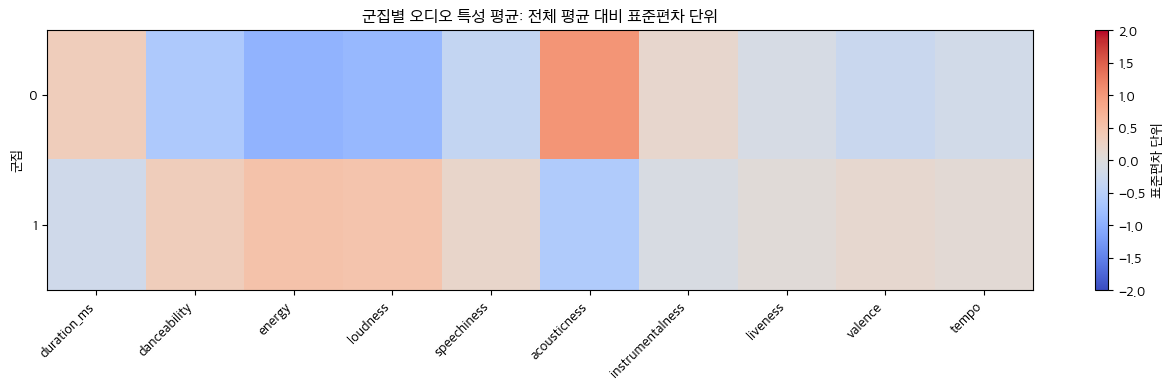

In [114]:
profile_cols = continuous_cols + ["danceability", "energy", "liveness", "valence"]
profile_cols = list(dict.fromkeys(c for c in profile_cols if c in df_final.columns))

cluster_profile = df_final.groupby("cluster")[profile_cols].mean()
cluster_profile.insert(0, "곡 수", df_final.groupby("cluster").size())
if "popularity" in df_final.columns:
    cluster_profile["인기도 중앙값"] = df_final.groupby("cluster")["popularity"].median()
display(cluster_profile.round(3))

# 표준화 특성의 군집별 평균을 색으로 표시해 상대적 특징을 읽습니다.
profile_z = (cluster_profile[continuous_cols] -
             df_final[continuous_cols].mean()) / df_final[continuous_cols].std(ddof=0)
fig, ax = plt.subplots(figsize=(13, max(4, 0.7 * len(profile_z))))
image = ax.imshow(profile_z, aspect="auto", cmap="coolwarm", vmin=-2, vmax=2)
ax.set_yticks(range(len(profile_z.index)))
ax.set_yticklabels([str(x) for x in profile_z.index])
ax.set_xticks(range(len(profile_z.columns)))
ax.set_xticklabels(profile_z.columns, rotation=45, ha="right")
ax.set_title("군집별 오디오 특성 평균: 전체 평균 대비 표준편차 단위")
ax.set_ylabel("군집")
plt.colorbar(image, ax=ax, label="표준편차 단위")
plt.tight_layout()
plt.show()

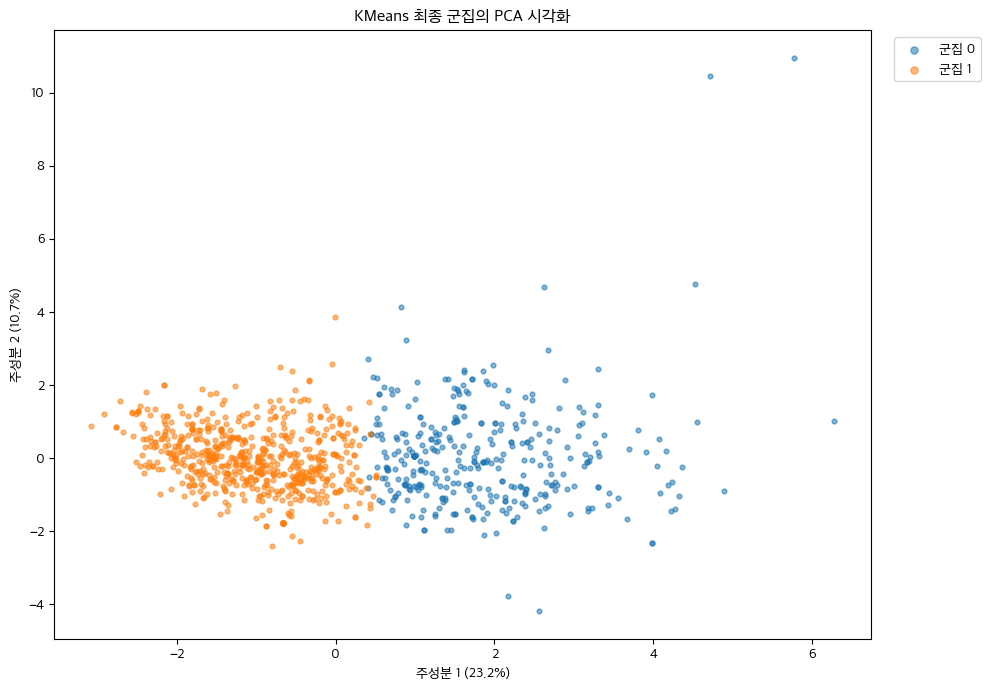

참고: K-Means/GMM은 전체 데이터에 적합했습니다. PCA 그래프만 보기 쉽게 최대 3,000곡을 표시합니다.


In [115]:
# PCA는 시각화를 위한 2차원 투영이며, 군집화 자체는 원래 특성 공간에서 수행했습니다.
viz_n = min(3000, len(df_final))
viz_df = df_final.sample(n=viz_n, random_state=RANDOM_STATE)
viz_X = X.loc[viz_df.index].to_numpy(dtype=np.float32)

pca = PCA(n_components=2, random_state=RANDOM_STATE)
viz_xy = pca.fit_transform(viz_X)
viz_labels = viz_df["cluster"].to_numpy()

fig, ax = plt.subplots(figsize=(10, 7))
for cluster_id in sorted(np.unique(viz_labels)):
    mask = viz_labels == cluster_id
    label = "잡음 (-1)" if cluster_id == -1 else f"군집 {cluster_id}"
    ax.scatter(
        viz_xy[mask, 0],
        viz_xy[mask, 1],
        s=12,
        alpha=0.55,
        label=label,
    )
ax.set_title(f"{FINAL_METHOD} 최종 군집의 PCA 시각화")
ax.set_xlabel(f"주성분 1 ({pca.explained_variance_ratio_[0]:.1%})")
ax.set_ylabel(f"주성분 2 ({pca.explained_variance_ratio_[1]:.1%})")
ax.legend(markerscale=1.5, bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

if FINAL_METHOD in ["KMeans", "GMM"]:
    print("참고: K-Means/GMM은 전체 데이터에 적합했습니다. PCA 그래프만 보기 쉽게 최대 3,000곡을 표시합니다.")
else:
    print("참고: DBSCAN/Mean Shift는 비교 표본에서만 적합했으며, 그래프도 해당 표본에서 표시합니다.")

## 다음 단계

1. 이 노트북을 위에서부터 실행하고, k-pop subset의 행 수와 비교표를 확인합니다.
2. 지표와 군집 크기, 결과 해석 가능성을 함께 고려해 FINAL_METHOD와 파라미터를 결정합니다.
3. 통계 검정은 최종 군집 결과에 대해 해석 보조자료로 사용합니다. p-value 하나로 최종 모델을 고르지 않습니다.
4. 이 결과는 `track_genre == "k-pop"` 라벨 subset에 대한 분석이며, 한국 가수만의 분석으로 단정하지 않습니다.
5. 마지막 셀에서 K-pop subset의 최종 K-Means track_id와 cluster 라벨을 웹에 내보냅니다. 웹은 같은 군집 안에서 코사인 유사도 순으로 추천합니다.


In [116]:
# 최종 test3 K-pop K-Means 라벨을 웹 추천기가 track_id로 연결할 수 있도록 내보냅니다.
if FINAL_METHOD != "KMeans":
    raise ValueError("웹 추천 결과 내보내기는 현재 K-Means 최종 모델만 지원합니다.")
web_data_candidates = [Path("spotify-recommender-web/cluster-data"),
                       Path("project2/spotify-recommender-web/cluster-data")]
web_data_dir = next((path for path in web_data_candidates if path.parent.exists()),
                    web_data_candidates[0])
web_data_dir.mkdir(parents=True, exist_ok=True)
cluster_export = df_final[["track_id", "cluster"]].copy()
cluster_export["track_id"] = cluster_export["track_id"].astype(str)
cluster_export["cluster"] = cluster_export["cluster"].astype(int)
cluster_export_path = web_data_dir / "test3_clusters.csv"
cluster_export.to_csv(cluster_export_path, index=False)
print(f"웹용 test3 군집 라벨 저장: {cluster_export_path} ({len(cluster_export):,}곡)")
display(cluster_export.groupby("cluster").size().rename("웹 내보내기 곡 수").to_frame())

웹용 test3 군집 라벨 저장: spotify-recommender-web/cluster-data/test3_clusters.csv (998곡)


,웹 내보내기 곡 수
cluster,
0,358
1,640
